# Instruction-following video model, T5

"put the red cube in the left box": frame t + instruction -> frame t+10, pixel U-Net,
clean-frame flow matching (`video.ipynb`'s recipe). The oracle IDM reads these futures at 59/60
with 0 wrong cube / bin (`experiments/idm/notes.md`), so colour and side are all on the video model.


In [3]:
%load_ext autoreload
%autoreload 2
from notebook_cache import NotebookCache

cache = NotebookCache('../cache/t5_video_nb')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Step 0: data

150 demos, 6 instruction pairs (the seen split); top frames already decoded.


In [4]:
import numpy as np
import pandas as pd
from lerobot.datasets.lerobot_dataset import LeRobotDataset

ROOT = '../data/robosuite/instructed_pick_place_clean_n150'
table = LeRobotDataset('dream_robot/instructed_pick_place_clean_n150', root=ROOT).hf_dataset
data = dict(
    state=np.asarray(table['observation.state'], dtype=np.float32),
    action=np.asarray(table['action'], dtype=np.float32),
    episode=np.asarray(table['episode_index']),
    task=np.asarray(table['task_index']),
    top=np.load(f'{ROOT}/decoded/top.npy'),  # [N, 3, 128, 128] uint8
)
prompts = pd.read_parquet(f'{ROOT}/meta/tasks.parquet').sort_values('task_index').index.tolist()
print({k: v.shape for k, v in data.items()})
print(prompts)

{'state': (33385, 8), 'action': (33385, 8), 'episode': (33385,), 'task': (33385,), 'top': (33385, 3, 128, 128)}
['put the green cube in the left box', 'put the yellow cube in the right box', 'put the blue cube in the left box', 'put the red cube in the left box', 'put the blue cube in the right box', 'put the red cube in the right box']


## Step 1: the scene

One demo per instruction: steps 0, 120, 180 and its last frame.


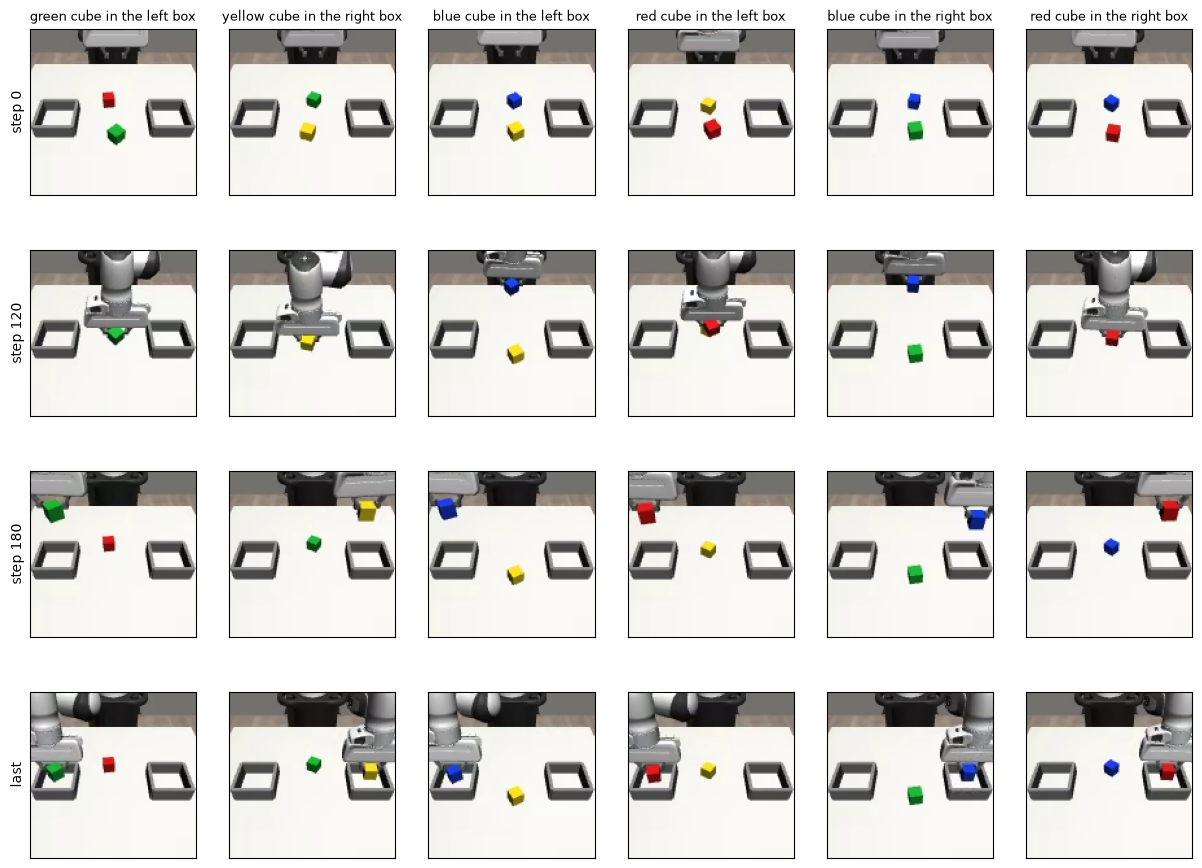

In [18]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(4, 6, figsize=(15, 11))
for task in range(6):
    rows = np.flatnonzero(data['episode'] == data['episode'][data['task'] == task][0])  # a demo
    for ax, row in zip(axs[:, task], [rows[0], rows[120], rows[180], rows[-1]]):
        ax.imshow(data['top'][row].transpose(1, 2, 0))
        ax.set(xticks=[], yticks=[])
    axs[0, task].set_title(prompts[task].removeprefix('put the '), fontsize=9)
for ax, name in zip(axs[:, 0], ['step 0', 'step 120', 'step 180', 'last']):
    ax.set_ylabel(name)

## Step 2: the instruction as a table

Two fields, each a learned vector inside the video model (step 3), summed:
colour (red / green / blue / yellow) and side (left / right). No language model, so a dream that
follows the fields follows the instruction itself. Held-out pairs (yellow-left, green-right) are new
combinations of seen fields. A task field (pick / place / both) comes once there are partial clips.
CLIP can replace this later.


In [5]:
COLOURS, SIDES = ['red', 'green', 'blue', 'yellow'], ['left', 'right']


def parse(prompt):
    # 'put the red cube in the left box' -> (colour index, side index)
    words = prompt.split()
    return COLOURS.index(words[2]), SIDES.index(words[6])


fields = np.array([parse(p) for p in prompts])  # [6 prompts, 2]
data = data | dict(colour=fields[data['task'], 0], side=fields[data['task'], 1])
for c, s in sorted(set(map(tuple, fields))):
    n = len(np.unique(data['episode'][(data['colour'] == c) & (data['side'] == s)]))
    print(f'{COLOURS[c]:6s} {SIDES[s]:5s} {n} demos')

red    left  32 demos
red    right 16 demos
green  left  27 demos
blue   left  20 demos
blue   right 22 demos
yellow right 33 demos


## Step 3: the instruction vector

One learned table per field; a row's instruction = colour vector + side vector, 256 numbers
(the width of the U-Net's bottom map, where step 4 adds it, as `video.ipynb` adds τ).


In [6]:
import torch
from torch import nn

dev = 'cuda'
instr = nn.ModuleDict(
    dict(colour=nn.Embedding(len(COLOURS), 256), side=nn.Embedding(len(SIDES), 256))
).to(dev)
rows = np.flatnonzero(data['episode'] == 0)[:3]
c = torch.tensor(data['colour'][rows], device=dev)
s = torch.tensor(data['side'][rows], device=dev)
print(COLOURS[c[0]], SIDES[s[0]], (instr['colour'](c) + instr['side'](s)).shape)

green left torch.Size([3, 256])


## Step 4: the U-Net with the instruction

`video.ipynb`'s U-Net, with step 3's two tables inside: colour + side vector added at the bottom
next to τ. Input [frame t, noisy t+10], output the clean frame t+10.


In [7]:
def down(i, o):
    # halves height and width
    return nn.Sequential(nn.Conv2d(i, o, 3, stride=2, padding=1), nn.GroupNorm(8, o), nn.SiLU())


def up(i, o):
    # doubles height and width
    return nn.Sequential(
        nn.Upsample(scale_factor=2), nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.SiLU()
    )


def tau_feats(tau):
    # [B] -> [B, 64]: sin/cos at 32 frequencies, 1..~1100
    f = tau[:, None] * torch.exp(torch.linspace(0, 7, 32, device=dev))
    return torch.cat([f.sin(), f.cos()], 1)

In [8]:
class UNet(nn.Module):
    # [frame t, noisy t+10] + tau + instruction (colour, side) -> clean frame t+10
    def __init__(self):
        super().__init__()
        self.down1, self.down2, self.down3 = down(6, 64), down(64, 128), down(128, 256)
        self.temb = nn.Sequential(nn.Linear(64, 256), nn.SiLU(), nn.Linear(256, 256))
        self.instr = nn.ModuleDict(
            dict(colour=nn.Embedding(len(COLOURS), 256), side=nn.Embedding(len(SIDES), 256))
        )
        self.up3, self.up2, self.up1 = up(256, 128), up(128 + 128, 64), up(64 + 64, 64)
        self.out = nn.Conv2d(64, 3, 1)

    def forward(self, now, noisy, tau, colour, side):
        h1 = self.down1(torch.cat([now, noisy], 1))
        h2 = self.down2(h1)
        bottom = self.temb(tau_feats(tau)) + self.instr['colour'](colour) + self.instr['side'](side)
        h3 = self.down3(h2) + bottom[:, :, None, None]
        u2 = self.up2(torch.cat([self.up3(h3), h2], 1))
        return self.out(self.up1(torch.cat([u2, h1], 1)))

In [9]:
def frames(rows):
    # rows -> top frames [B, 3, 128, 128] in [-1, 1] on the GPU
    return torch.tensor(data['top'][rows], device=dev).float() / 127.5 - 1


unet = UNet().to(dev)
rows = np.flatnonzero(data['episode'] == 0)[:3]
colour, side = (torch.tensor(data[k][rows], device=dev) for k in ('colour', 'side'))
noise, tau = torch.randn(3, 3, 128, 128, device=dev), torch.rand(3, device=dev)
with torch.no_grad():
    out = unet(frames(rows), noise, tau, colour, side)
print(out.shape, f'{sum(p.numel() for p in unet.parameters()) / 1e6:.2f}M params')

torch.Size([3, 3, 128, 128]) 0.97M params


## Step 5: train

10 demos held out. Rows t whose t+10 is in the same demo. Clean-frame flow matching:

```-
noisy = (1 - τ)·noise + τ·future      loss = mse(net(now, noisy, τ, colour, side), future)
```

Val loss every 1000 steps on 512 held-out rows, noise and τ fixed.


In [10]:
K = 10  # frames ahead
ok = np.flatnonzero(data['episode'][:-K] == data['episode'][K:])  # rows t with t+K in the same demo
val_demos = np.random.default_rng(0).permutation(150)[:10]
split = dict(
    train=ok[~np.isin(data['episode'][ok], val_demos)],
    val=ok[np.isin(data['episode'][ok], val_demos)],
)
print({k: len(v) for k, v in split.items()})

{'train': 29762, 'val': 2123}


In [11]:
from frozendict import frozendict


def fields(rows):
    # rows -> (colour, side) index tensors on the GPU
    return torch.tensor(data['colour'][rows], device=dev), torch.tensor(
        data['side'][rows], device=dev
    )


@cache
def train(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # a fresh UNet -> weights (CPU), log rows [step, train loss, val loss]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 3, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )
    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            frames(b + K),
            torch.randn(B, 3, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (
                (net(frames(b), (1 - tw) * noise + tw * fut, tau, *fields(b)).float() - fut)
                .square()
                .mean()
            )
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vl = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = frames(vb + K), t[:, None, None, None]
                    pred = net(frames(vb), (1 - tw) * n + tw * fut, t, *fields(vb)).float()
                    vl += (pred - fut).square().mean().item() / 8
            log.append([step, loss.item(), vl])
            print(f'{step:5d}  train {loss.item():.4f}   val {vl:.4f}', flush=True)
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train: cached, 1 call(s) stored


In [13]:
run = train()

 1000  train 0.0127   val 0.0132
 2000  train 0.0084   val 0.0109
 3000  train 0.0057   val 0.0099
 4000  train 0.0076   val 0.0088
 5000  train 0.0083   val 0.0082
 6000  train 0.0063   val 0.0078
 7000  train 0.0061   val 0.0074
 8000  train 0.0061   val 0.0071
 9000  train 0.0042   val 0.0070
10000  train 0.0055   val 0.0069


## Step 6: does it follow the instruction?

One held-out start frame, four instructions (each of the scene's two cubes, each side).
A dream is 10 steps; chaining 15 of them (each dream becomes the next frame t) shows where the arm goes.


In [14]:
net = UNet().to(dev).eval()
net.load_state_dict(run['weights'])


@torch.no_grad()
def dream(now, colour, side, n=20, seed=0):
    # frame t [B, 3, 128, 128] in [-1, 1], instruction indices [B] -> dreamed frame t+K, n Euler steps
    x = torch.randn(now.shape, device=dev, generator=torch.Generator(device=dev).manual_seed(seed))
    for i in range(n):
        tau = i / n
        x = (
            x
            + (net(now, x, torch.full((len(now),), tau, device=dev), colour, side) - x)
            / (1 - tau)
            / n
        )
    return x.clamp(-1, 1)

In [12]:
import json

attempts = json.load(open(f'{ROOT}/instructions.json'))[
    'attempts'
]  # one per demo, in order (all kept)
demo = int(val_demos[0])
scene = attempts[demo]
print(demo, scene['prompt'], '| other cube:', scene['distractor_color'])

71 put the red cube in the left box | other cube: green


In [15]:
start = frames(np.flatnonzero(data['episode'] == demo)[:1]).repeat(4, 1, 1, 1)  # [4, 3, 128, 128]
asks = [(col, side) for col in (scene['color'], scene['distractor_color']) for side in SIDES]
colour = torch.tensor([COLOURS.index(col) for col, _ in asks], device=dev)
side = torch.tensor([SIDES.index(s) for _, s in asks], device=dev)
chain = [start]
for _ in range(15):
    chain.append(dream(chain[-1], colour, side))

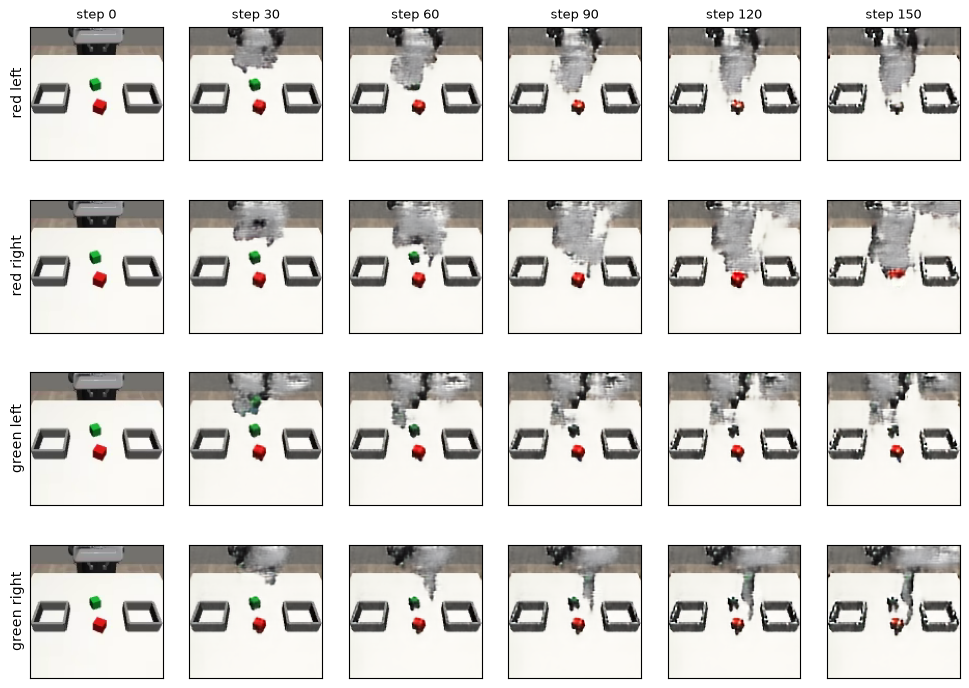

In [16]:
show = [0, 3, 6, 9, 12, 15]  # chunks: 0, 30, ..., 150 steps
fig, axs = plt.subplots(4, len(show), figsize=(2 * len(show), 8.6))
for i, (col, s) in enumerate(asks):
    for ax, j in zip(axs[i], show):
        ax.imshow((chain[j][i].cpu().numpy().transpose(1, 2, 0) + 1) / 2)
        ax.set(xticks=[], yticks=[])
    axs[i, 0].set_ylabel(f'{col} {s}')
for ax, j in zip(axs[0], show):
    ax.set_title(f'step {10 * j}', fontsize=9)

Chained dreams blur into mush, so test one dream at a time, from real frames, at the two moments the
instruction decides: the approach (which cube?) and just after the lift (which box?).


In [17]:
rows71 = np.flatnonzero(data['episode'] == demo)
grasp = int(np.argmax(data['action'][rows71, 7] < 0.5))  # first step the gripper command closes
moments = dict(approach=rows71[40], lifted=rows71[grasp + 30])
print('grasp at step', grasp, '| test frames at steps 40 and', grasp + 30)

grasp at step 88 | test frames at steps 40 and 118


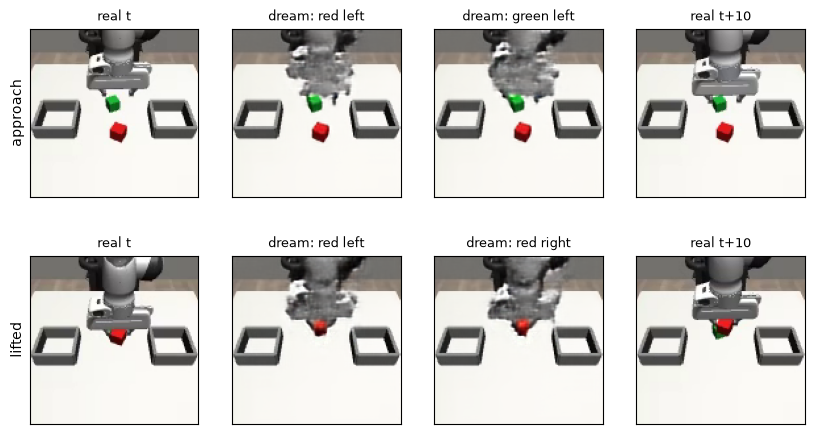

In [18]:
tests = dict(
    approach=[
        (col, scene['side']) for col in (scene['color'], scene['distractor_color'])
    ],  # swap colour
    lifted=[(scene['color'], s) for s in SIDES],  # swap side
)
fig, axs = plt.subplots(2, 4, figsize=(10, 5.4))
for row, (name, asks) in zip(axs, tests.items()):
    now = frames([moments[name]] * 2)
    colour = torch.tensor([COLOURS.index(col) for col, _ in asks], device=dev)
    side = torch.tensor([SIDES.index(s) for _, s in asks], device=dev)
    pics = [now[0], *dream(now, colour, side), frames([moments[name] + K])[0]]
    titles = ['real t', *[f'dream: {col} {s}' for col, s in asks], 'real t+10']
    for ax, pic, title in zip(row, pics, titles):
        ax.imshow((pic.cpu().numpy().transpose(1, 2, 0) + 1) / 2)
        ax.set(xticks=[], yticks=[])
        ax.set_title(title, fontsize=9)
    row[0].set_ylabel(name)

## Step 7: a top-camera IDM

`idm.ipynb`'s IDM, here on T5: (frame t, frame t+10, joints) -> the 10 actions in between.
Conv encoder, spatial-softmax keypoints per frame, MLP head. Trained on real frames.


In [19]:
C_KP = 32  # keypoints per frame


def keypoints(maps):
    # [B, C, h, w] -> [B, C, 2]: each channel's softmax-weighted (x, y), in [-1, 1]
    _, _, h, w = maps.shape
    p = maps.flatten(2).softmax(-1).unflatten(2, (h, w))
    xs, ys = torch.linspace(-1, 1, w, device=dev), torch.linspace(-1, 1, h, device=dev)
    return torch.stack([(p.sum(2) * xs).sum(-1), (p.sum(3) * ys).sum(-1)], -1)


class IDM(nn.Module):
    # frames t, t+K [B, 3, 128, 128] in [-1, 1], joints [B, 8] (std units) -> actions [B, K, 8] (std units)
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(down(3, 32), down(32, 64), down(64, 64), nn.Conv2d(64, C_KP, 1))
        self.head = nn.Sequential(
            nn.Linear(3 * C_KP * 2 + 8, 256),
            nn.GELU(),
            nn.Linear(256, 256),
            nn.GELU(),
            nn.Linear(256, K * 8),
        )

    def forward(self, f0, f1, joints):
        now, fut = keypoints(self.enc(f0)).flatten(1), keypoints(self.enc(f1)).flatten(1)
        return self.head(torch.cat([now, fut, fut - now, joints], 1)).view(-1, K, 8)

In [20]:
tr = split['train']
stats = dict(
    s_mean=data['state'][tr].mean(0), s_std=data['state'][tr].std(0),
    a_mean=data['action'][tr].mean(0),
    a_std=data['action'][tr].std(0),
)


@cache
def train_idm(steps: int = 10000, B: int = 64, lr: float = 1e-3, seed: int = 0):
    # a fresh IDM -> weights (CPU), log rows [step, train loss, val arm error, val gripper right]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    idm = IDM().to(dev)
    opt = torch.optim.AdamW(idm.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    va = data['action'][vr[:, None] + np.arange(K)]

    def read(b):
        joints = torch.tensor((data['state'][b] - stats['s_mean']) / stats['s_std'], device=dev)
        return idm(frames(b), frames(b + K), joints)

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(tr, B)
        target = torch.tensor(
            (data['action'][b[:, None] + np.arange(K)] - stats['a_mean']) / stats['a_std'],
            device=dev,
        )
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (read(b).float() - target).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            with torch.no_grad():
                pred = torch.cat([read(c).float() for c in np.split(vr, 8)]).cpu().numpy()
            pred = pred * stats['a_std'] + stats['a_mean']
            arm = ((pred - va)[..., :7] ** 2).mean()
            grip = ((pred[..., 7] > 0.5) == (va[..., 7] > 0.5)).mean()
            log.append([step, loss.item(), arm, grip])
            print(
                f'{step:5d}  train {loss.item():.4f}   val arm {arm:.5f}  gripper right {grip:.1%}',
                flush=True,
            )
    return frozendict(weights={k: v.cpu() for k, v in idm.state_dict().items()}, log=np.array(log))

train_idm: cached, 1 call(s) stored


In [21]:
run_idm = train_idm()

 1000  train 0.0140   val arm 0.00022  gripper right 98.7%
 2000  train 0.0099   val arm 0.00013  gripper right 99.1%
 3000  train 0.0072   val arm 0.00009  gripper right 99.3%
 4000  train 0.0051   val arm 0.00008  gripper right 99.3%
 5000  train 0.0054   val arm 0.00007  gripper right 99.5%
 6000  train 0.0062   val arm 0.00007  gripper right 99.6%
 7000  train 0.0057   val arm 0.00006  gripper right 99.6%
 8000  train 0.0041   val arm 0.00006  gripper right 99.6%
 9000  train 0.0038   val arm 0.00006  gripper right 99.6%
10000  train 0.0036   val arm 0.00006  gripper right 99.6%


## Step 8: closed loop

Every 10 steps: the video model dreams frame t+10 from the live top camera and the episode's
instruction (parsed from its prompt), the IDM reads the 10 actions, the robot plays them.
Seen pairs, seeds 1000-1019 (SmolVLA's eval seeds). Oracle IDM (both cameras, real futures): 47/60.


In [22]:
import logging
import os

os.environ.setdefault('MUJOCO_GL', 'egl')
logging.disable(logging.WARNING)
from dream_robot.sims.robosuite.tasks.instructed_pick_place.env import (
    InstructedPickPlace,
    TaskConfig,
)

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)
idm = IDM().to(dev).eval()
idm.load_state_dict(run_idm['weights'])

<All keys matched successfully>

In [23]:
def to_t(img):
    # camera image [128, 128, 3] uint8 -> [1, 3, 128, 128] in [-1, 1] on the GPU
    return torch.tensor(img, device=dev).permute(2, 0, 1)[None].float() / 127.5 - 1


@torch.no_grad()
def plan(obs, colour, side):
    # live observation + instruction indices [1] -> 10 actions [K, 8] in joint units
    now = to_t(obs.images['top'])
    joints = torch.tensor((obs.state - stats['s_mean']) / stats['s_std'], device=dev)[None]
    acts = (
        idm(now, dream(now, colour, side), joints)[0].cpu().numpy() * stats['a_std']
        + stats['a_mean']
    )
    acts[:, 7] = acts[:, 7].clip(0, 1)
    return acts


def rollout(env, seed):
    # one episode -> (success, failure mode, which half of the instruction it got wrong, steps)
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    t = 0
    while True:
        if t % K == 0:
            acts = plan(obs, colour, side)
        res = env.step(acts[t % K])
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )

In [24]:
from collections import Counter


@cache
def evaluate(pairs: str = 'seen', start: int = 1000, n: int = 20):
    # n episodes from seed start, instructions from the pairs split -> {seed: rollout(...)}
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    return {seed: rollout(env, seed) for seed in range(start, start + n)}

evaluate: not cached, will compute


In [25]:
res = evaluate()
print(f'video model + IDM, seen pairs: {sum(ok for ok, *_ in res.values())}/20')
print('failures', Counter(m for ok, m, *_ in res.values() if not ok))
print('instruction half wrong', Counter(w for ok, _, w, _ in res.values() if not ok))

video model + IDM, seen pairs: 0/20
failures Counter({'no_grasp': 19, 'wrong_target': 1})
instruction half wrong Counter({None: 19, 'wrong_cube': 1})


Film a no_grasp episode: [real top camera | the dream the current 10 actions were read from].


In [21]:
@torch.no_grad()
def film(env, seed):
    # rollout(), keeping every step's [real frame | current dream], 2x upscaled -> (frames, result)
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    shots, t = [], 0
    while True:
        if t % K == 0:
            now = to_t(obs.images['top'])
            fut = dream(now, colour, side)
            joints = torch.tensor((obs.state - stats['s_mean']) / stats['s_std'], device=dev)[None]
            acts = idm(now, fut, joints)[0].cpu().numpy() * stats['a_std'] + stats['a_mean']
            acts[:, 7] = acts[:, 7].clip(0, 1)
            pic = ((fut[0] + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()
        shots.append(np.concatenate([obs.images['top'], pic], 1).repeat(2, 0).repeat(2, 1))
        res = env.step(acts[t % K])
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return shots, (res.success, str(res.failure_mode), env.prompt)

In [31]:
import imageio
from IPython.display import Video

shots, result = film(InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template'), 1000)
print(result)
imageio.mimsave('../scratch/t5_video_seed1000.mp4', shots, fps=20)
Video('../scratch/t5_video_seed1000.mp4', embed=True, width=512)

NameError: name 'film' is not defined

In [28]:
# diagnosis only (sim state): seed 1000 again, hand's xy distance to each cube every 50 steps
env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
obs, t = env.reset(seed=1000), 0
colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
while t < 600:
    if t % K == 0:
        acts = plan(obs, colour, side)
    if t % 50 == 0:
        hand = env.mujoco[1].site('gripper0_right_grip_site').xpos
        named, other = (
            np.linalg.norm(hand[:2] - env.cube_pos[:2]),
            np.linalg.norm(hand[:2] - env.distractor_pos[:2]),
        )
        print(
            f'{t:3d}  to yellow (named) {named:.3f} m   to green {other:.3f} m   hand z {hand[2]:.3f}'
        )
    res = env.step(acts[t % K])
    obs, t = res.observation, t + 1

  0  to yellow (named) 0.053 m   to green 0.197 m   hand z 1.011
 50  to yellow (named) 0.088 m   to green 0.066 m   hand z 0.915
100  to yellow (named) 0.133 m   to green 0.019 m   hand z 0.849
150  to yellow (named) 0.104 m   to green 0.052 m   hand z 0.888
200  to yellow (named) 0.153 m   to green 0.048 m   hand z 0.944
250  to yellow (named) 0.134 m   to green 0.086 m   hand z 0.930
300  to yellow (named) 0.133 m   to green 0.133 m   hand z 0.904
350  to yellow (named) 0.146 m   to green 0.171 m   hand z 0.876
400  to yellow (named) 0.138 m   to green 0.184 m   hand z 0.860
450  to yellow (named) 0.123 m   to green 0.183 m   hand z 0.861
500  to yellow (named) 0.052 m   to green 0.164 m   hand z 0.847
550  to yellow (named) 0.050 m   to green 0.165 m   hand z 0.887


## Step 9: does the model use the instruction?

On 512 held-out rows: dream error against the real frame t+10 with the true instruction, with
the colour swapped to the other cube's, and with the side swapped. Error only on pixels that move
from t to t+10 (the arm and the cube), as in `video.ipynb`. If a swap barely hurts, that field is ignored.


In [20]:
def moving_err(guess, now, fut):
    # all [B, 3, 128, 128] in [-1, 1] -> (squared error summed over moving pixels, their count)
    moving = ((fut - now).abs() / 2 > 0.05).any(1, keepdim=True).expand_as(fut)
    return (((guess - fut) / 2) ** 2)[moving].sum().item(), moving.sum().item()


other = np.array([COLOURS.index(a['distractor_color']) for a in attempts])[
    data['episode']
]  # per row

In [30]:
vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
tot = {'true': [0, 0], 'colour swapped': [0, 0], 'side swapped': [0, 0]}
for b in np.split(vr, 8):
    now, fut = frames(b), frames(b + K)
    colour, side = fields(b)
    asks = {
        'true': (colour, side),
        'colour swapped': (torch.tensor(other[b], device=dev), side),
        'side swapped': (colour, 1 - side),
    }
    for name, (c_, s_) in asks.items():
        e, n = moving_err(dream(now, c_, s_), now, fut)
        tot[name][0] += e
        tot[name][1] += n
for name, (e, n) in tot.items():
    print(f'{name:15s} moving mse {e / n:.4f}')

true            moving mse 0.0466
colour swapped  moving mse 0.0487
side swapped    moving mse 0.0488


The average mixes in frames where the swap can't matter. Per held-out demo: colour window = start
to grasp (gripper command closes), side window = grasp to release (it reopens). Each swap scored only
in its own window, on every held-out row there.


In [21]:
closed = data['action'][:, 7] < 0.5
window = np.zeros(len(closed), dtype='<U6')  # per row: 'colour', 'side' or ''
for e in val_demos:
    r = np.flatnonzero(data['episode'] == e)
    g = r[np.argmax(closed[r])]  # grasp row
    rel = g + np.argmax(~closed[g : r[-1] + 1])  # first row after it with the gripper open again
    window[r[0] : g], window[g:rel] = 'colour', 'side'
rows_in = {w: split['val'][window[split['val']] == w] for w in ('colour', 'side')}
print({w: len(v) for w, v in rows_in.items()})

{'colour': 762, 'side': 1361}


In [32]:
for w, swap in [('colour', 'colour swapped'), ('side', 'side swapped')]:
    tot = {'true': [0, 0], swap: [0, 0]}
    for b in np.array_split(rows_in[w], len(rows_in[w]) // 64 + 1):
        now, fut = frames(b), frames(b + K)
        colour, side = fields(b)
        bad = (torch.tensor(other[b], device=dev), side) if w == 'colour' else (colour, 1 - side)
        for name, (c_, s_) in [('true', (colour, side)), (swap, bad)]:
            e, n = moving_err(dream(now, c_, s_), now, fut)
            tot[name][0] += e
            tot[name][1] += n
    print(f'{w} window: ' + '   '.join(f'{name} {e / n:.4f}' for name, (e, n) in tot.items()))

colour window: true 0.0401   colour swapped 0.0408
side window: true 0.0485   side swapped 0.0526


The decision is a moment, not a window: once the arm is moving, the frame shows the choice. So the swap's
effect in 10-step bins: colour by steps from the start, side by steps after the grasp.


In [22]:
offset = np.full(
    len(closed), -1
)  # per held-out row: steps from start (colour) or after the grasp (side)
for e in val_demos:
    r = np.flatnonzero(data['episode'] == e)
    g = r[np.argmax(closed[r])]
    offset[r[0] : g] = np.arange(g - r[0])
    offset[g : r[-1] + 1] = np.arange(r[-1] + 1 - g)


def swap_cost(rows, which):
    # held-out rows -> moving mse with the swapped field / with the true instruction
    now, fut = frames(rows), frames(rows + K)
    colour, side = fields(rows)
    bad = (torch.tensor(other[rows], device=dev), side) if which == 'colour' else (colour, 1 - side)
    true_e, n = moving_err(dream(now, colour, side), now, fut)
    swap_e, _ = moving_err(dream(now, *bad), now, fut)
    return swap_e / true_e

In [34]:
for w in ('colour', 'side'):
    rows = rows_in[w]
    line = []
    for lo in range(0, 200, 10):
        b = rows[(offset[rows] >= lo) & (offset[rows] < lo + 10)]
        if len(b):
            line.append(f'{lo:3d}: {swap_cost(b, w):.2f} ({len(b)})')
    print(f'{w}:\n  ' + '\n  '.join(line))

colour:
    0: 1.01 (100)
   10: 1.01 (100)
   20: 1.01 (100)
   30: 1.02 (100)
   40: 1.02 (100)
   50: 1.02 (93)
   60: 1.01 (60)
   70: 1.03 (60)
   80: 1.02 (39)
   90: 1.08 (10)
side:
    0: 1.00 (100)
   10: 1.00 (100)
   20: 0.99 (100)
   30: 1.00 (100)
   40: 1.00 (100)
   50: 1.04 (100)
   60: 1.14 (100)
   70: 1.33 (100)
   80: 1.31 (100)
   90: 1.27 (100)
  100: 1.25 (100)
  110: 1.18 (100)
  120: 1.11 (75)
  130: 1.10 (52)
  140: 1.10 (32)
  150: 1.00 (2)


## Step 10: the instruction at every level (FiLM)

The conditioning vector (τ + colour + side) reaches only the 16x16 bottom now, where the two cubes
share cells. Here every block gets it: a linear layer turns it into a scale and a shift per channel,
`out * (1 + scale) + shift`. The fine 64x64 / 128x128 maps can then pick out the named cube.


In [12]:
class UNet2(nn.Module):
    # step 4's UNet, with the conditioning vector FiLM-ing every block
    def __init__(self):
        super().__init__()
        self.temb = nn.Sequential(nn.Linear(64, 256), nn.SiLU(), nn.Linear(256, 256))
        self.instr = nn.ModuleDict(
            dict(colour=nn.Embedding(len(COLOURS), 256), side=nn.Embedding(len(SIDES), 256))
        )
        self.blocks = nn.ModuleDict(
            dict(
                down1=down(6, 64), down2=down(64, 128), down3=down(128, 256),
                up3=up(256, 128), up2=up(128 + 128, 64), up1=up(64 + 64, 64),
            )
        )
        widths = dict(down1=64, down2=128, down3=256, up3=128, up2=64, up1=64)
        self.film = nn.ModuleDict({k: nn.Linear(256, 2 * w) for k, w in widths.items()})
        self.out = nn.Conv2d(64, 3, 1)

    def forward(self, now, noisy, tau, colour, side):
        c = (
            self.temb(tau_feats(tau)) + self.instr['colour'](colour) + self.instr['side'](side)
        )  # [B, 256]

        def block(name, x):
            scale, shift = self.film[name](c)[:, :, None, None].chunk(2, 1)
            return self.blocks[name](x) * (1 + scale) + shift

        h1 = block('down1', torch.cat([now, noisy], 1))
        h2 = block('down2', h1)
        h3 = block('down3', h2)
        u2 = block('up2', torch.cat([block('up3', h3), h2], 1))
        return self.out(block('up1', torch.cat([u2, h1], 1)))

In [36]:
unet2 = UNet2().to(dev)
probe = dict(
    rows=np.flatnonzero(data['episode'] == 0)[:3], noise=torch.randn(3, 3, 128, 128, device=dev)
)
with torch.no_grad():
    out = unet2(
        frames(probe['rows']), probe['noise'], torch.rand(3, device=dev), *fields(probe['rows'])
    )
print(out.shape, f'{sum(p.numel() for p in unet2.parameters()) / 1e6:.2f}M params')

torch.Size([3, 3, 128, 128]) 1.34M params


In [24]:
@cache
def train2(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # step 5's train(), with a fresh UNet2 -> weights (CPU), log rows [step, train loss, val loss]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet2().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 3, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )
    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            frames(b + K),
            torch.randn(B, 3, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (
                (net(frames(b), (1 - tw) * noise + tw * fut, tau, *fields(b)).float() - fut)
                .square()
                .mean()
            )
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vl = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = frames(vb + K), t[:, None, None, None]
                    pred = net(frames(vb), (1 - tw) * n + tw * fut, t, *fields(vb)).float()
                    vl += (pred - fut).square().mean().item() / 8
            log.append([step, loss.item(), vl])
            print(f'{step:5d}  train {loss.item():.4f}   val {vl:.4f}', flush=True)
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train2: cached, 2 call(s) stored


In [25]:
run2 = train2()

 1000  train 0.0135   val 0.0145
 2000  train 0.0085   val 0.0108
 3000  train 0.0056   val 0.0093
 4000  train 0.0068   val 0.0084
 5000  train 0.0077   val 0.0075
 6000  train 0.0057   val 0.0071
 7000  train 0.0054   val 0.0066
 8000  train 0.0055   val 0.0062
 9000  train 0.0036   val 0.0061
10000  train 0.0047   val 0.0060


`net` now points at the trained UNet2, so `dream`, `swap_cost` and `plan` all use it. Same swap bins as step 9.


In [39]:
net = UNet2().to(dev).eval()
net.load_state_dict(run2['weights'])

<All keys matched successfully>

In [40]:
for w in ('colour', 'side'):
    rows = rows_in[w]
    line = []
    for lo in range(0, 200, 10):
        b = rows[(offset[rows] >= lo) & (offset[rows] < lo + 10)]
        if len(b):
            line.append(f'{lo:3d}: {swap_cost(b, w):.2f} ({len(b)})')
    print(f'{w}:\n  ' + '\n  '.join(line))

AcceleratorError: CUDA error: the launch timed out and was terminated
Search for `cudaErrorLaunchTimeout' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


Closed loop with UNet2 (step 8's loop; step 5's net: 0/20, 19 no_grasp).


In [26]:
@cache
def evaluate2(pairs: str = 'seen', start: int = 1000, n: int = 20):
    # step 8's evaluate() with net = UNet2 -> {seed: rollout(...)}
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    return {seed: rollout(env, seed) for seed in range(start, start + n)}

evaluate2: cached, 1 call(s) stored


In [29]:
res = evaluate2()
print(f'UNet2 + IDM, seen pairs: {sum(ok for ok, *_ in res.values())}/20')
print('failures', Counter(m for ok, m, *_ in res.values() if not ok))
print('instruction half wrong', Counter(w for ok, _, w, _ in res.values() if not ok))

UNet2 + IDM, seen pairs: 1/20
failures Counter({'no_grasp': 18, 'wrong_target': 1})
instruction half wrong Counter({None: 18, 'wrong_cube': 1})


Why no_grasp? Diagnosis only (sim state): per step, the hand's xy distance to the named cube and to the
other one, and its height above the named cube.


In [30]:
@torch.no_grad()
def trace(env, seed):
    # rollout() with net = UNet2 -> [steps, 3]: xy distance to named cube, to the other, hand height above named
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    rows, t = [], 0
    while True:
        if t % K == 0:
            acts = plan(obs, colour, side)
        hand = env.mujoco[1].site('gripper0_right_grip_site').xpos
        rows.append(
            [
                np.linalg.norm(hand[:2] - env.cube_pos[:2]),
                np.linalg.norm(hand[:2] - env.distractor_pos[:2]),
                hand[2] - env.cube_pos[2],
            ]
        )
        res = env.step(acts[t % K])
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return np.array(rows)

In [ ]:
env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
for seed in range(1000, 1005):
    tr_ = trace(env, seed)
    near = tr_[:300, 0] < tr_[:300, 1]  # first 300 steps: closer to the named cube than the other?
    lo = tr_[:, 2].argmin()
    print(
        f'{seed}  closer to named {near.mean():.0%} of steps 0-300   lowest at step {lo}: '
        f'{100 * tr_[lo, 2]:.1f} cm above named, {100 * tr_[lo, 0]:.1f} cm from it in xy, {100 * tr_[lo, 1]:.1f} from other'
    )

1000  closer to named 16% of steps 0-300   lowest at step 248: 0.5 cm above named, 10.8 cm from it in xy, 4.4 from other
1001  closer to named 30% of steps 0-300   lowest at step 137: 1.2 cm above named, 9.3 cm from it in xy, 4.9 from other
1002  closer to named 11% of steps 0-300   lowest at step 89: 2.2 cm above named, 13.1 cm from it in xy, 1.6 from other
1003  closer to named 32% of steps 0-300   lowest at step 82: 0.8 cm above named, 9.0 cm from it in xy, 4.3 from other
1004  closer to named 28% of steps 0-300   lowest at step 205: -1.1 cm above named, 9.1 cm from it in xy, 7.2 from other


A position habit? Per seed: which slot the instruction named (0 = the cube nearer the robot) and which
slot the arm spent steps 0-300 nearer to. Demos: target in slot 0 in 65 of 150.


In [ ]:
went = {}
for seed in range(1000, 1010):
    tr_ = trace(env, seed)
    named = env.instruction.target_slot
    went[seed] = (named, named if (tr_[:300, 0] < tr_[:300, 1]).mean() > 0.5 else 1 - named)
    print(
        seed,
        env.prompt.removeprefix('put the '),
        '| named slot',
        went[seed][0],
        '| arm went to slot',
        went[seed][1],
    )
print('arm went to slot 0 in', sum(g == 0 for _, g in went.values()), 'of', len(went))

1000 yellow cube in the right box | named slot 0 | arm went to slot 1
1001 green cube in the left box | named slot 0 | arm went to slot 1
1002 yellow cube in the right box | named slot 0 | arm went to slot 1
1003 yellow cube in the right box | named slot 0 | arm went to slot 1
1004 blue cube in the left box | named slot 0 | arm went to slot 1
1005 yellow cube in the right box | named slot 0 | arm went to slot 0
1006 red cube in the left box | named slot 0 | arm went to slot 0
1007 yellow cube in the right box | named slot 0 | arm went to slot 1
1008 blue cube in the right box | named slot 1 | arm went to slot 0
1009 red cube in the right box | named slot 1 | arm went to slot 0
arm went to slot 0 in 4 of 10


First 120 steps of two wrong-cube seeds, every 10 steps: [real frame t | the dream the next 10 actions come from].


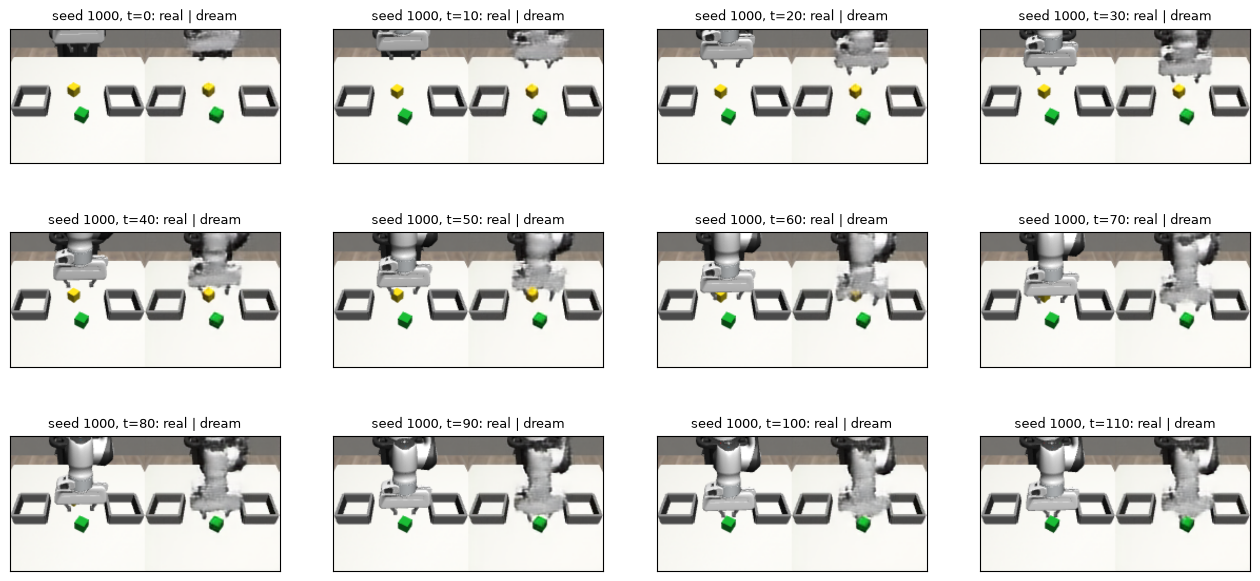

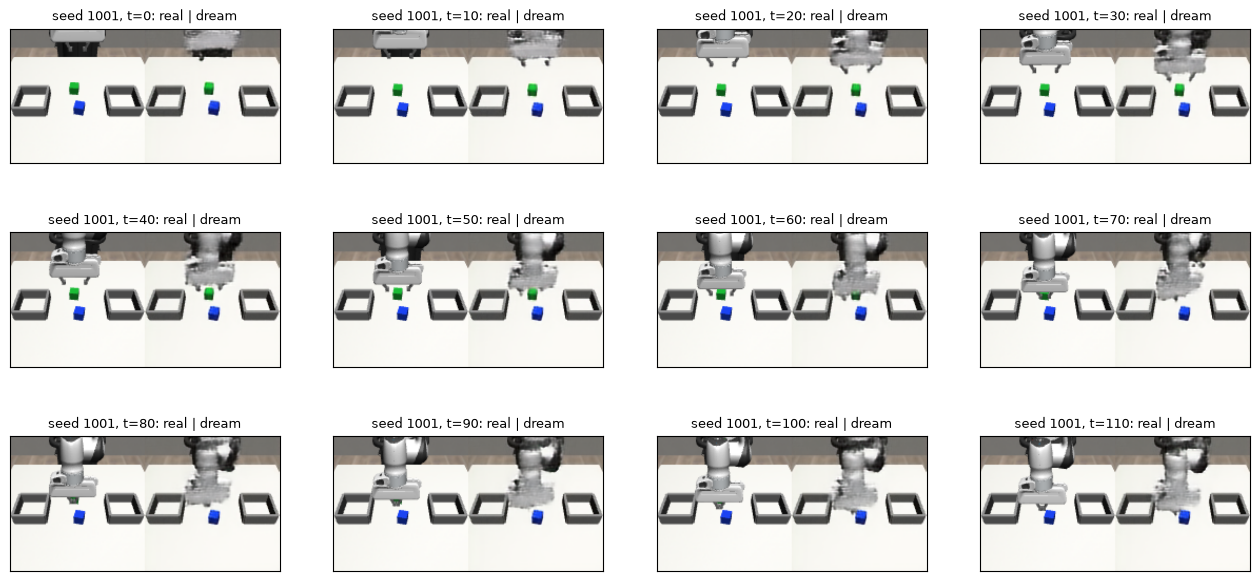

In [ ]:
for seed in (1000, 1001):
    shots, _ = film(env, seed)
    fig, axs = plt.subplots(3, 4, figsize=(16, 7.5))
    for ax, t in zip(axs.flat, range(0, 120, 10)):
        ax.imshow(shots[t])
        ax.set(xticks=[], yticks=[])
        ax.set_title(f'seed {seed}, t={t}: real | dream', fontsize=9)

## Step 11: train longer

The arm reaches the named cube, but the grasp-moment dreams erase the cube under the fingers.
Under-trained? Same UNet2, 30k steps instead of 10k (val at 10k: 0.0060).


In [31]:
run3 = train2(steps=30000)

 1000  train 0.0135   val 0.0145
 2000  train 0.0087   val 0.0108
 3000  train 0.0058   val 0.0093
 4000  train 0.0069   val 0.0095
 5000  train 0.0076   val 0.0076
 6000  train 0.0058   val 0.0071
 7000  train 0.0053   val 0.0063
 8000  train 0.0052   val 0.0060
 9000  train 0.0037   val 0.0057
10000  train 0.0041   val 0.0054
11000  train 0.0047   val 0.0051
12000  train 0.0043   val 0.0050
13000  train 0.0029   val 0.0050
14000  train 0.0039   val 0.0047
15000  train 0.0041   val 0.0045
16000  train 0.0023   val 0.0044
17000  train 0.0038   val 0.0044
18000  train 0.0035   val 0.0043
19000  train 0.0042   val 0.0042
20000  train 0.0035   val 0.0042
21000  train 0.0030   val 0.0041
22000  train 0.0027   val 0.0041
23000  train 0.0035   val 0.0040
24000  train 0.0028   val 0.0039
25000  train 0.0036   val 0.0039
26000  train 0.0047   val 0.0039
27000  train 0.0032   val 0.0039
28000  train 0.0031   val 0.0039
29000  train 0.0031   val 0.0039
30000  train 0.0039   val 0.0039


`net` -> the 30k-step UNet2. Same grasp-moment strips as step 10, then the closed loop.


In [32]:
net = UNet2().to(dev).eval()
net.load_state_dict(run3['weights'])

<All keys matched successfully>

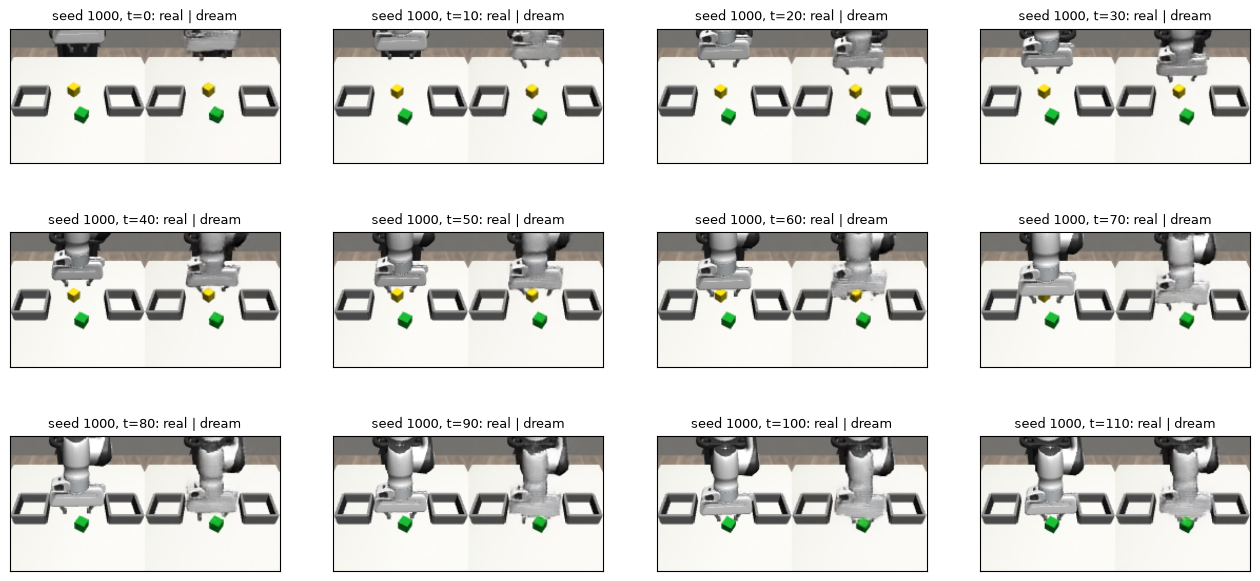

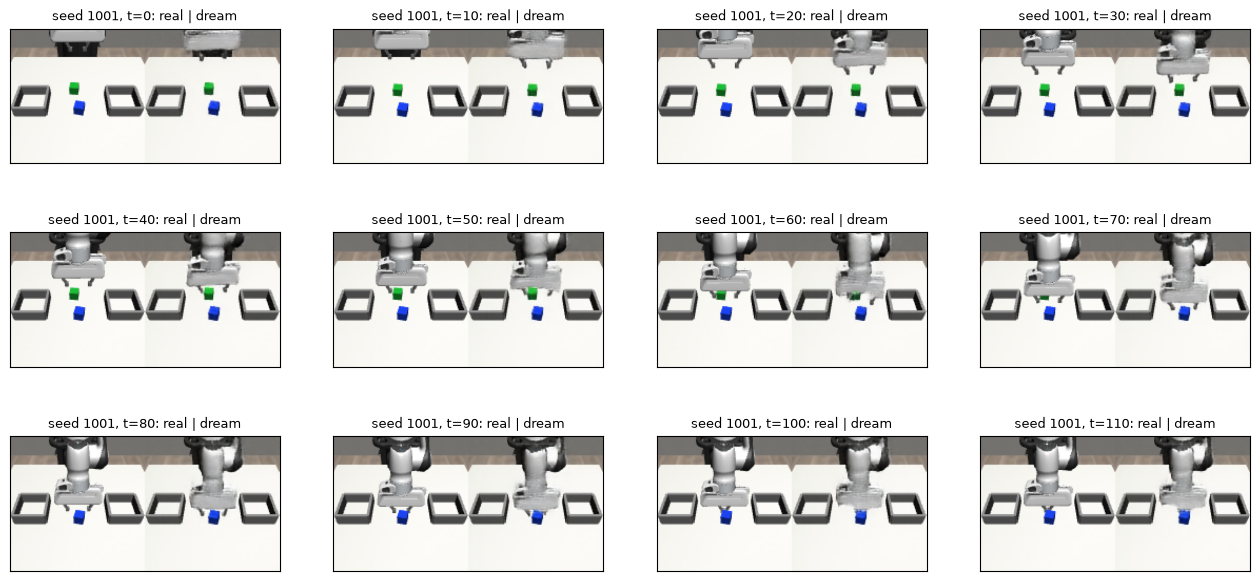

In [34]:
import matplotlib.pyplot as plt

env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
for seed in (1000, 1001):
    shots, _ = film(env, seed)
    fig, axs = plt.subplots(3, 4, figsize=(16, 7.5))
    for ax, t in zip(axs.flat, range(0, 120, 10)):
        ax.imshow(shots[t])
        ax.set(xticks=[], yticks=[])
        ax.set_title(f'seed {seed}, t={t}: real | dream', fontsize=9)

In [35]:
@cache
def evaluate3(pairs: str = 'seen', start: int = 1000, n: int = 20):
    # step 8's evaluate() with net = the 30k-step UNet2 -> {seed: rollout(...)}
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    return {seed: rollout(env, seed) for seed in range(start, start + n)}

evaluate3: not cached, will compute


In [36]:
res = evaluate3()
print(f'UNet2 30k + IDM, seen pairs: {sum(ok for ok, *_ in res.values())}/20')
print('failures', Counter(m for ok, m, *_ in res.values() if not ok))
print('instruction half wrong', Counter(w for ok, _, w, _ in res.values() if not ok))

UNet2 30k + IDM, seen pairs: 1/20
failures Counter({'no_grasp': 18, 'wrong_target': 1})
instruction half wrong Counter({None: 18, 'wrong_cube': 1})


## Step 12: the wrist camera as input

At the grasp the gripper hides the named cube from the top camera; the wrist camera sees it between
the fingers. UNet3 = UNet2 with [top t, wrist t] as the condition; it still dreams only the top frame,
so the IDM stays top-only.


In [13]:
data = data | dict(
    wrist=np.load(f'{ROOT}/decoded/wrist.npy')
)  # [N, 3, 128, 128] uint8, same rows as top


def wframes(rows):
    # rows -> wrist frames [B, 3, 128, 128] in [-1, 1] on the GPU
    return torch.tensor(data['wrist'][rows], device=dev).float() / 127.5 - 1

In [38]:
class UNet3(UNet2):
    # UNet2 with the wrist frame t as a third input: [top t, wrist t, noisy top t+10] -> clean top t+10
    def __init__(self):
        super().__init__()
        self.blocks['down1'] = down(9, 64)

    def forward(self, now, wrist, noisy, tau, colour, side):
        return super().forward(torch.cat([now, wrist], 1), noisy, tau, colour, side)

In [39]:
@cache
def train3(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # step 10's train2(), with a fresh UNet3 (wrist t as input) -> weights (CPU), log rows [step, train loss, val loss]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet3().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 3, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )
    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            frames(b + K),
            torch.randn(B, 3, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            loss = (
                (
                    net(frames(b), wframes(b), (1 - tw) * noise + tw * fut, tau, *fields(b)).float()
                    - fut
                )
                .square()
                .mean()
            )
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vl = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = frames(vb + K), t[:, None, None, None]
                    pred = net(
                        frames(vb), wframes(vb), (1 - tw) * n + tw * fut, t, *fields(vb)
                    ).float()
                    vl += (pred - fut).square().mean().item() / 8
            log.append([step, loss.item(), vl])
            print(f'{step:5d}  train {loss.item():.4f}   val {vl:.4f}', flush=True)
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train3: not cached, will compute


In [ ]:
run4 = train3(steps=30000)

## Step 13: our IDM on perfect futures

Is the IDM the broken link at the grasp? Same loop, but the frame t+10 comes from the expert played
10 steps ahead in a rewound copy of the sim (the repo's `ExpertFuture`), not from the video model.
Repo's oracle IDM (both cameras): 47/60 this way, every failure a hover over the slot-0 cube.


In [49]:
from dream_robot.sims.robosuite.oracle import ExpertFuture
from dream_robot.sims.robosuite.tasks.instructed_pick_place.expert import ExpertPolicy


@torch.no_grad()
def rollout_oracle(env, seed):
    # one episode, our top IDM reading the expert's real frame t+10 -> (success, failure mode, half wrong, steps)
    obs = env.reset(seed=seed)
    future = ExpertFuture(env, ExpertPolicy(env), spacing=K, horizon=K)
    future.reset()
    t = 0
    while True:
        clip = future.observe(obs, imagine=t % K == 0)
        if clip is not None:
            joints = torch.tensor((obs.state - stats['s_mean']) / stats['s_std'], device=dev)[None]
            acts = (
                idm(to_t(obs.images['top']), to_t(clip[0].images['top']), joints)[0].cpu().numpy()
            )
            acts = acts * stats['a_std'] + stats['a_mean']
            acts[:, 7] = acts[:, 7].clip(0, 1)
        res = env.step(acts[t % K])
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )

In [66]:
@cache(2)  # 2: the oracle replanned at every grasp (fixed in oracle.py)
def evaluate_oracle(pairs: str = 'seen', start: int = 1000, n: int = 20):
    # rollout_oracle() on n seeds -> {seed: result}
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    return {seed: rollout_oracle(env, seed) for seed in range(start, start + n)}

evaluate_oracle: not cached, will compute


In [67]:
res = evaluate_oracle()
print(f'oracle future + our top IDM, seen pairs: {sum(ok for ok, *_ in res.values())}/20')
print('failures', Counter(m for ok, m, *_ in res.values() if not ok))
print('failed seeds', [s for s, (ok, *_) in res.items() if not ok])

oracle future + our top IDM, seen pairs: 4/20
failures Counter({'no_grasp': 12, 'dropped': 4})
failed seeds [1000, 1002, 1003, 1004, 1005, 1006, 1007, 1009, 1010, 1011, 1012, 1013, 1014, 1016, 1017, 1019]


Same oracle loop with the repo's IDM (`experiments/idm/k10`: top + wrist, 60 epochs, shift augmentation,
L1). Its own eval gave 47/60 on seeds 1000-1059; here the first 20.


In [25]:
from pathlib import Path

from dream_robot.core.registry import POLICIES


@cache(2)  # 2: the oracle replanned at every grasp (fixed in oracle.py)
def evaluate_repo_idm(pairs: str = 'seen', start: int = 1000, n: int = 20):
    # the repo's oracle_idm policy (expert future, k=10) on n seeds -> {seed: (success, mode, half wrong, steps)}
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    policy = POLICIES['oracle_idm'](env, checkpoint=Path('../experiments/idm/k10/checkpoint.pt'))
    out = {}
    for seed in range(start, start + n):
        obs = env.reset(seed=seed)
        policy.reset()
        t = 0
        while True:
            res = env.step(policy(obs))
            obs, t = res.observation, t + 1
            if res.terminated or res.truncated:
                out[seed] = (
                    res.success,
                    str(res.failure_mode),
                    None if res.success else env.instruction_failure(),
                    t,
                )
                break
    return out

evaluate_repo_idm: cached, 1 call(s) stored


In [69]:
res = evaluate_repo_idm()
print(f'oracle future + repo IDM (top + wrist): {sum(ok for ok, *_ in res.values())}/20')
print('failures', Counter(m for ok, m, *_ in res.values() if not ok))
print('failed seeds', [s for s, (ok, *_) in res.items() if not ok])

oracle future + repo IDM (top + wrist): 14/20
failures Counter({'no_grasp': 6})
failed seeds [1002, 1003, 1007, 1010, 1011, 1016]


Whole-clip oracle (the repo's 59/60 mode): the expert imagines the rest of the episode once, a frame
every 10 steps; the IDM walks the clip, (real frame now, next clip frame); a new clip only when it runs out.


In [24]:
@torch.no_grad()
def rollout_oracle_full(env, seed):
    # rollout_oracle() with one whole-episode clip per imagination -> (success, failure mode, half wrong, steps)
    obs = env.reset(seed=seed)
    future = ExpertFuture(env, ExpertPolicy(env), spacing=K, horizon=None)
    future.reset()
    clip, t = [], 0
    while True:
        need = t % K == 0
        fresh = future.observe(obs, imagine=need and not clip)
        if fresh is not None:
            clip = list(fresh)
        if need:
            joints = torch.tensor((obs.state - stats['s_mean']) / stats['s_std'], device=dev)[None]
            acts = (
                idm(to_t(obs.images['top']), to_t(clip.pop(0).images['top']), joints)[0]
                .cpu()
                .numpy()
            )
            acts = acts * stats['a_std'] + stats['a_mean']
            acts[:, 7] = acts[:, 7].clip(0, 1)
        res = env.step(acts[t % K])
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def evaluate_oracle_full(pairs: str = 'seen', start: int = 1000, n: int = 20):
    # rollout_oracle_full() on n seeds -> {seed: result}
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    return {seed: rollout_oracle_full(env, seed) for seed in range(start, start + n)}

evaluate_oracle_full: cached, 1 call(s) stored


In [71]:
res = evaluate_oracle_full()
print(
    f'whole-clip oracle + our top IDM: {sum(ok for ok, *_ in res.values())}/20   (10-step oracle: 4/20)'
)
print('failures', Counter(m for ok, m, *_ in res.values() if not ok))

whole-clip oracle + our top IDM: 10/20   (10-step oracle: 4/20)
failures Counter({'dropped': 5, 'no_grasp': 5})


## Step 14: both IDMs, both oracle modes, 60 seeds

Seeds 1000-1059 (the repo's October eval). Repo IDM in October: 47/60 (10-step), 59/60 (whole clip).
Episodes run in worker processes (the kernel would run one at a time). `multiprocess` (dill) sends
the notebook's own functions to fresh spawned workers; fork broke MuJoCo's offscreen rendering.


In [26]:
import dill
import multiprocess as mp

dill.settings['recurse'] = True  # send only the globals a function uses, not the whole notebook


def oracle_job(job):
    # (reader 'ours' / 'repo', mode 'step' / 'clip', pairs, seed) -> (success, failure mode, half wrong, steps)
    reader, mode, pairs, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    if reader == 'ours':
        return (rollout_oracle if mode == 'step' else rollout_oracle_full)(env, seed)
    policy = POLICIES['oracle_idm'](
        env,
        checkpoint=Path('../experiments/idm/k10/checkpoint.pt'),
        horizon='k' if mode == 'step' else None,
    )
    obs, t = env.reset(seed=seed), 0
    policy.reset()
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


def quiet():
    # worker start: mute robosuite's import-time warnings and info lines
    import logging

    logging.disable(logging.WARNING)
    import robosuite  # noqa: F401

    logging.disable(logging.NOTSET)
    logging.getLogger('robosuite_logs').setLevel(logging.ERROR)


def in_parallel(jobs, workers=4):
    # oracle_job over jobs in spawned worker processes -> results in job order
    # each worker holds its own torch + CUDA + sim (~2-3 GB): 8 ran this 31 GB machine out of memory
    with mp.get_context('spawn').Pool(workers, initializer=quiet) as pool:
        return pool.map(oracle_job, jobs, chunksize=1)

In [38]:
@cache
def oracle_grid(n: int = 60, start: int = 1000, pairs: str = 'seen'):
    # both IDMs x both oracle modes on n seeds -> {(reader, mode): {seed: result}}
    jobs = [
        (r, m, pairs, s)
        for r in ('ours', 'repo')
        for m in ('step', 'clip')
        for s in range(start, start + n)
    ]
    grid = {}
    for (r, m, _, s), result in zip(jobs, in_parallel(jobs)):
        grid.setdefault((r, m), {})[s] = result
    return grid

oracle_grid: cached, 1 call(s) stored


In [28]:
grid = oracle_grid()
for (who, mode), r in grid.items():
    fails = Counter(m for ok, m, *_ in r.values() if not ok)
    print(f'{who:5s} {mode:5s} {sum(ok for ok, *_ in r.values())}/{len(r)}   {dict(fails)}')

ours  step  24/60   {'dropped': 10, 'no_grasp': 26}
ours  clip  37/60   {'dropped': 7, 'no_grasp': 16}
repo  step  47/60   {'no_grasp': 12, 'dropped': 1}
repo  clip  59/60   {'no_grasp': 1}


## Step 15: dream both cameras

UNet3's inputs (top t, wrist t), but it dreams the wrist frame t+10 too, so the repo IDM (top + wrist, 47/60 on oracle futures) can read the dreams instead of our top-only IDM (24/60).


In [14]:
class UNet4(UNet2):
    # [top t, wrist t, noisy top t+10, noisy wrist t+10] -> clean [top t+10, wrist t+10] (6 channels)
    def __init__(self):
        super().__init__()
        self.blocks['down1'] = down(12, 64)
        self.out = nn.Conv2d(64, 6, 1)

    def forward(self, now, wrist, noisy, tau, colour, side):
        return super().forward(torch.cat([now, wrist], 1), noisy, tau, colour, side)

In [15]:
unet4 = UNet4().to(dev)
rows = np.flatnonzero(data['episode'] == 0)[:3]
with torch.no_grad():
    out = unet4(
        frames(rows), wframes(rows), torch.randn(3, 6, 128, 128, device=dev),
        torch.rand(3, device=dev), *fields(rows),
    )
print(out.shape, f'{sum(p.numel() for p in unet4.parameters()) / 1e6:.2f}M params')

torch.Size([3, 6, 128, 128]) 1.34M params


In [16]:
@cache
def train4(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # train3() with a fresh UNet4 (dreams top + wrist) -> weights (CPU), log rows [step, train loss, val top, val wrist]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet4().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 6, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )

    def both(rows):
        # rows -> [B, 6, 128, 128]: top and wrist frames stacked on channels
        return torch.cat([frames(rows), wframes(rows)], 1)

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            both(b + K),
            torch.randn(B, 6, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            pred = net(frames(b), wframes(b), (1 - tw) * noise + tw * fut, tau, *fields(b))
            loss = (pred.float() - fut).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vt = vw = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = both(vb + K), t[:, None, None, None]
                    err = (
                        net(
                            frames(vb), wframes(vb), (1 - tw) * n + tw * fut, t, *fields(vb)
                        ).float()
                        - fut
                    ).square()
                    vt += err[:, :3].mean().item() / 8
                    vw += err[:, 3:].mean().item() / 8
            log.append([step, loss.item(), vt, vw])
            print(
                f'{step:5d}  train {loss.item():.4f}   val top {vt:.4f}  wrist {vw:.4f}', flush=True
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train4: not cached, will compute


In [17]:
run5 = train4(steps=30000)

 1000  train 0.0163   val top 0.0192  wrist 0.0249
 2000  train 0.0143   val top 0.0134  wrist 0.0198
 3000  train 0.0137   val top 0.0114  wrist 0.0177
 4000  train 0.0107   val top 0.0103  wrist 0.0160
 5000  train 0.0097   val top 0.0093  wrist 0.0147
 6000  train 0.0093   val top 0.0087  wrist 0.0137
 7000  train 0.0138   val top 0.0084  wrist 0.0130
 8000  train 0.0093   val top 0.0078  wrist 0.0122
 9000  train 0.0069   val top 0.0078  wrist 0.0117
10000  train 0.0116   val top 0.0072  wrist 0.0113
11000  train 0.0064   val top 0.0071  wrist 0.0112
12000  train 0.0101   val top 0.0070  wrist 0.0106
13000  train 0.0069   val top 0.0067  wrist 0.0103
14000  train 0.0090   val top 0.0066  wrist 0.0104
15000  train 0.0073   val top 0.0063  wrist 0.0100
16000  train 0.0086   val top 0.0063  wrist 0.0101
17000  train 0.0067   val top 0.0061  wrist 0.0096
18000  train 0.0057   val top 0.0061  wrist 0.0093
19000  train 0.0062   val top 0.0060  wrist 0.0092
20000  train 0.0090   val top 0

## Step 16: UNet4's dreams, read by the repo IDM

Closed loop: every 10 steps UNet4 dreams top + wrist 10 steps ahead, the repo IDM (top + wrist; 47/60 on the oracle's perfect futures, step 14) reads [real now, dream] -> 10 actions. First a look at the dreams around the grasp.


In [ ]:
net4 = UNet4().to(dev).eval()
net4.load_state_dict(run5['weights'])


@torch.no_grad()
def dream4(now, wrist, colour, side, n=20, seed=0):
    # top, wrist t [B, 3, 128, 128] in [-1, 1], instruction [B] -> dreamed (top, wrist) t+K, n Euler steps
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn(len(now), 6, 128, 128, device=dev, generator=g)
    for i in range(n):
        tau = i / n
        x = (
            x
            + (net4(now, wrist, x, torch.full((len(now),), tau, device=dev), colour, side) - x)
            / (1 - tau)
            / n
        )
    x = x.clamp(-1, 1)
    return x[:, :3], x[:, 3:]

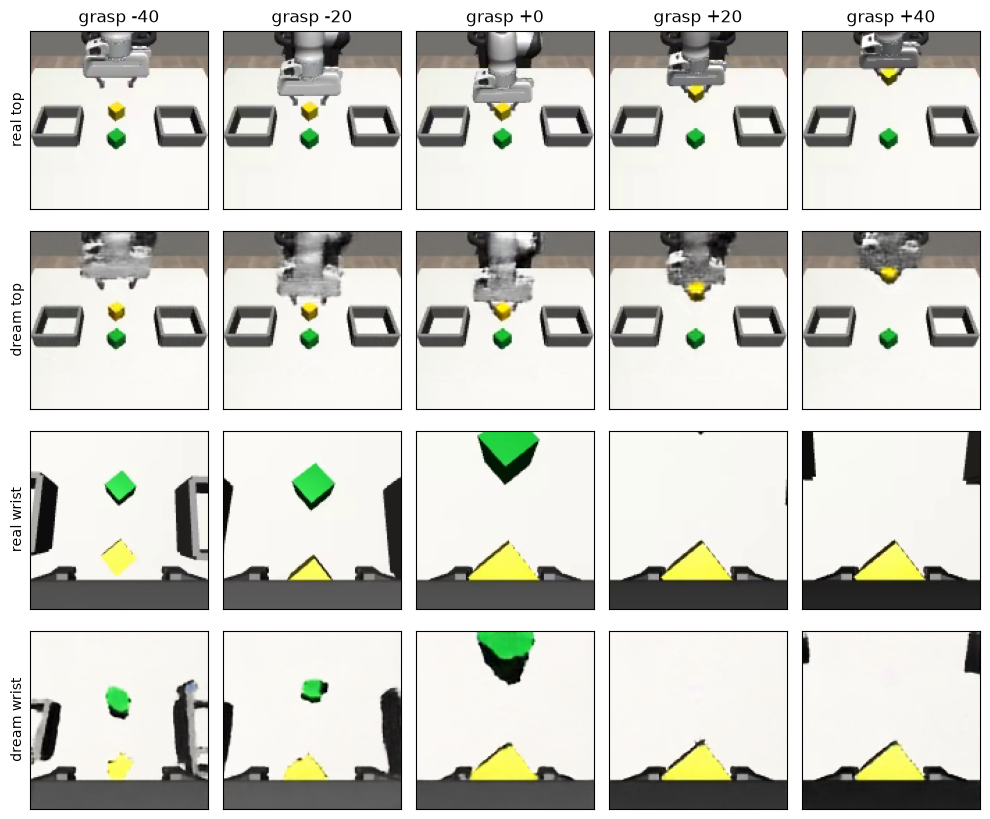

In [28]:
# one held-out demo, 5 moments around the grasp: rows = real top t+10, dream, real wrist t+10, dream
ev = data['episode'][split['val'][0]]
er = np.flatnonzero(data['episode'] == ev)
g0 = int(np.argmax(data['action'][er, 7] < 0.5))  # first step the gripper command closes
ts = er[[g0 - 40, g0 - 20, g0, g0 + 20, g0 + 40]]
top4, wrist4 = dream4(frames(ts), wframes(ts), *fields(ts))
show4 = [frames(ts + K), top4, wframes(ts + K), wrist4]
names = ['real top', 'dream top', 'real wrist', 'dream wrist']
fig, axs = plt.subplots(4, 5, figsize=(10, 8.4))
for r, (imgs, name) in enumerate(zip(show4, names)):
    for c in range(5):
        axs[r, c].imshow(((imgs[c].permute(1, 2, 0) + 1) / 2).float().cpu().numpy())
        axs[r, c].set_xticks([]), axs[r, c].set_yticks([])
        if c == 0:
            axs[r, c].set_ylabel(name)
        if r == 0:
            axs[r, c].set_title(f'grasp {[-40, -20, 0, 20, 40][c]:+d}')
plt.tight_layout()
plt.show()

In [ ]:
from dream_robot.core.schema import Observation
from dream_robot.policies.idm.policy import IDMPolicy

REPO_IDM = Path('../experiments/idm/k10/checkpoint.pt')


def to_img(x):
    # [1, 3, 128, 128] in [-1, 1] -> camera image [128, 128, 3] uint8
    return ((x[0].permute(1, 2, 0) + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()


class DreamFuture:
    # IDMPolicy's future source: UNet4's dream of top + wrist K steps ahead, a one-frame clip
    def __init__(self, colour, side):
        self.colour, self.side = colour, side

    def reset(self):
        pass

    def observe(self, obs, imagine):
        if not imagine:
            return None
        top, wrist = dream4(
            to_t(obs.images['top']), to_t(obs.images['wrist']), self.colour, self.side
        )
        return [Observation(state=obs.state, images={'top': to_img(top), 'wrist': to_img(wrist)})]


def vm_job(job):
    # (pairs, seed) -> (success, failure mode, half wrong, steps): UNet4 dreams, repo IDM reads them
    pairs, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    policy = IDMPolicy(IDMPolicy.load_net(REPO_IDM, dev)[0], DreamFuture(colour, side), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def vm_grid(n: int = 60, start: int = 1000, pairs: str = 'seen'):
    # vm_job on n seeds, 8 spawned workers -> {seed: result}
    jobs = [(pairs, s) for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(range(start, start + n), pool.map(vm_job, jobs, chunksize=1)))

vm_grid: not cached, will compute


In [30]:
res = vm_grid()
fails = Counter(m for ok, m, *_ in res.values() if not ok)
print(f'UNet4 dreams + repo IDM: {sum(ok for ok, *_ in res.values())}/60   {dict(fails)}')
print('half wrong:', dict(Counter(h for ok, _, h, _ in res.values() if not ok)))

UNet4 dreams + repo IDM: 4/60   {'no_grasp': 43, 'wrong_target': 10, 'dropped': 3}
half wrong: {None: 46, 'wrong_cube': 10}


Film failed episodes: [real top | dream top | real wrist | dream wrist] each step (the dream the current 10 actions were read from), and the gripper command every 20 steps.


In [ ]:
import imageio
from IPython.display import Markdown


def film4(seed, pairs='seen'):
    # one vm_job episode -> (frames [T, 128, 512, 3] uint8, gripper commands [T], result)
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    policy = IDMPolicy(IDMPolicy.load_net(REPO_IDM, dev)[0], DreamFuture(colour, side), device=dev)
    policy.reset()
    shots, grip, t = [], [], 0
    while True:
        a = policy(obs)
        aim = policy.aim_images
        shots.append(
            np.concatenate([obs.images['top'], aim['top'], obs.images['wrist'], aim['wrist']], 1)
        )
        grip.append(float(a[7]))
        res = env.step(a)
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                np.stack(shots),
                np.array(grip),
                (env.prompt, res.success, str(res.failure_mode), t),
            )


picks = [s for s, r in res.items() if r[1] == 'no_grasp'][:2] + [
    s for s, r in res.items() if r[1] == 'wrong_target'
][:1]
for seed in picks:
    shots, grip, out = film4(seed)
    imageio.mimwrite(f'../scratch/vm4_seed{seed}.mp4', shots, fps=20)
    print(seed, out)
    display(Markdown(f'[vm4_seed{seed}.mp4](../scratch/vm4_seed{seed}.mp4)'))
    print('   gripper cmd every 20 steps:', ' '.join(f'{g:.2f}' for g in grip[::20]))

1000 ('put the yellow cube in the right box', False, 'no_grasp', 600)


[vm4_seed1000.mp4](../scratch/vm4_seed1000.mp4)

   gripper cmd every 20 steps: 0.99 0.99 0.98 0.99 1.00 0.03 0.06 0.05 0.03 0.03 0.03 0.06 0.05 0.02 0.02 0.02 0.02 0.02 0.02 0.03 0.04 0.06 0.08 0.08 0.15 0.05 0.02 0.01 0.01 0.03
1001 ('put the green cube in the left box', False, 'no_grasp', 600)


[vm4_seed1001.mp4](../scratch/vm4_seed1001.mp4)

   gripper cmd every 20 steps: 0.96 1.00 0.98 0.99 0.99 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00
1002 ('put the yellow cube in the right box', False, 'wrong_target', 600)


[vm4_seed1002.mp4](../scratch/vm4_seed1002.mp4)

   gripper cmd every 20 steps: 1.00 0.99 0.99 0.98 0.96 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.07 0.02 0.02 0.01 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00


In [36]:
for seed in [s for s, r in res.items() if r[0]]:  # the 4 successes
    shots, grip, out = film4(seed)
    imageio.mimwrite(f'../scratch/vm4_seed{seed}.mp4', shots, fps=20)
    print(seed, out)
    display(Markdown(f'[vm4_seed{seed}.mp4](../scratch/vm4_seed{seed}.mp4)'))

1021 ('put the red cube in the left box', True, 'none', 268)


[vm4_seed1021.mp4](../scratch/vm4_seed1021.mp4)

1025 ('put the yellow cube in the right box', True, 'none', 223)


[vm4_seed1025.mp4](../scratch/vm4_seed1025.mp4)

1042 ('put the blue cube in the right box', True, 'none', 229)


[vm4_seed1042.mp4](../scratch/vm4_seed1042.mp4)

1054 ('put the yellow cube in the right box', True, 'none', 243)


[vm4_seed1054.mp4](../scratch/vm4_seed1054.mp4)

Successes look like far-cube instructions only. Per seed (sim state, diagnosis only): the named cube's slot (0 = nearer the robot) vs the result.


In [ ]:
env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
slot = {}
for seed in res:
    env.reset(seed=seed)
    slot[seed] = env.instruction.target_slot
for s in (0, 1):
    rs = [res[k] for k in res if slot[k] == s]
    print(
        f'named slot {s} ({"near" if s == 0 else "far"}): {sum(r[0] for r in rs)}/{len(rs)}',
        dict(Counter(r[1] for r in rs)),
    )

named slot 0 (near): 0/39 {'no_grasp': 29, 'wrong_target': 10}
named slot 1 (far): 4/21 {'no_grasp': 14, 'dropped': 3, 'none': 4}


## Step 17: memory, frame t-60

UNet4 is 0/39 when the named cube is the near one (the arm hides it) and 4/21 for the far one. Give it top + wrist at t-60 as memory (the episode's first frame before step 60). One far frame, not t-10 / t-20: close past frames hand the model the arm's velocity, which it copied on T1.


In [ ]:
P = 60  # memory: frames this far back
first = np.unique(data['episode'], return_index=True)[1][
    data['episode']
]  # each row's episode start row
past = np.maximum(
    np.arange(len(data['episode'])) - P, first
)  # row t -> row t-60, clamped to the start
print(past[first[0] : first[0] + 3], past[first[0] + 100])

[0 0 0] 40


In [40]:
class UNet5(UNet2):
    # [top t, wrist t, top t-60, wrist t-60, noisy top + wrist t+10] -> clean [top t+10, wrist t+10]
    def __init__(self):
        super().__init__()
        self.blocks['down1'] = down(18, 64)
        self.out = nn.Conv2d(64, 6, 1)

    def forward(self, now, wrist, p_top, p_wrist, noisy, tau, colour, side):
        return super().forward(torch.cat([now, wrist, p_top, p_wrist], 1), noisy, tau, colour, side)

In [ ]:
unet5 = UNet5().to(dev)
rows = np.flatnonzero(data['episode'] == 0)[:3]
with torch.no_grad():
    out = unet5(
        frames(rows), wframes(rows), frames(past[rows]), wframes(past[rows]),
        torch.randn(3, 6, 128, 128, device=dev), torch.rand(3, device=dev),
        *fields(rows),
    )
print(out.shape, f'{sum(p.numel() for p in unet5.parameters()) / 1e6:.2f}M params')

torch.Size([3, 6, 128, 128]) 1.34M params


In [ ]:
@cache
def train5(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0):
    # train4() with a fresh UNet5 (+ top, wrist at t-60) -> weights (CPU), log rows [step, train loss, val top, val wrist]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet5().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 6, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )

    def both(rows):
        # rows -> [B, 6, 128, 128]: top and wrist frames stacked on channels
        return torch.cat([frames(rows), wframes(rows)], 1)

    def inputs(rows):
        # rows -> (top t, wrist t, top t-60, wrist t-60)
        return frames(rows), wframes(rows), frames(past[rows]), wframes(past[rows])

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            both(b + K),
            torch.randn(B, 6, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        with torch.autocast('cuda', dtype=torch.bfloat16):
            pred = net(*inputs(b), (1 - tw) * noise + tw * fut, tau, *fields(b))
            loss = (pred.float() - fut).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vt = vw = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = both(vb + K), t[:, None, None, None]
                    err = (
                        net(*inputs(vb), (1 - tw) * n + tw * fut, t, *fields(vb)).float() - fut
                    ).square()
                    vt += err[:, :3].mean().item() / 8
                    vw += err[:, 3:].mean().item() / 8
            log.append([step, loss.item(), vt, vw])
            print(
                f'{step:5d}  train {loss.item():.4f}   val top {vt:.4f}  wrist {vw:.4f}', flush=True
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train5: not cached, will compute


In [43]:
run6 = train5(steps=30000)

 1000  train 0.0155   val top 0.0174  wrist 0.0249
 2000  train 0.0135   val top 0.0134  wrist 0.0195
 3000  train 0.0139   val top 0.0120  wrist 0.0171
 4000  train 0.0105   val top 0.0098  wrist 0.0154
 5000  train 0.0093   val top 0.0091  wrist 0.0142
 6000  train 0.0090   val top 0.0084  wrist 0.0131
 7000  train 0.0129   val top 0.0079  wrist 0.0128
 8000  train 0.0084   val top 0.0074  wrist 0.0118
 9000  train 0.0064   val top 0.0075  wrist 0.0114
10000  train 0.0111   val top 0.0068  wrist 0.0112
11000  train 0.0063   val top 0.0068  wrist 0.0107
12000  train 0.0099   val top 0.0065  wrist 0.0104
13000  train 0.0065   val top 0.0064  wrist 0.0101
14000  train 0.0084   val top 0.0061  wrist 0.0098
15000  train 0.0073   val top 0.0060  wrist 0.0098
16000  train 0.0075   val top 0.0060  wrist 0.0096
17000  train 0.0062   val top 0.0059  wrist 0.0092
18000  train 0.0057   val top 0.0057  wrist 0.0091
19000  train 0.0058   val top 0.0056  wrist 0.0089
20000  train 0.0086   val top 0

Closed loop with UNet5: the future source keeps every live frame, so the dream gets the real t-60 (the first frame before step 60). Same 60 seeds, split by the named cube's slot (cell above step 17).


In [ ]:
net5 = UNet5().to(dev).eval()
net5.load_state_dict(run6['weights'])


@torch.no_grad()
def dream5(now, wrist, p_top, p_wrist, colour, side, n=20, seed=0):
    # dream4() for UNet5: + top, wrist t-60 [B, 3, 128, 128] in [-1, 1] -> dreamed (top, wrist) t+K
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn(len(now), 6, 128, 128, device=dev, generator=g)
    for i in range(n):
        tau = i / n
        v = net5(
            now, wrist, p_top, p_wrist, x, torch.full((len(now),), tau, device=dev), colour, side
        )
        x = x + (v - x) / (1 - tau) / n
    x = x.clamp(-1, 1)
    return x[:, :3], x[:, 3:]

In [ ]:
class DreamFuture5:
    # DreamFuture with memory: remembers every live frame, dreams from (t, t-60)
    def __init__(self, colour, side):
        self.colour, self.side = colour, side

    def reset(self):
        self.seen = []

    def observe(self, obs, imagine):
        self.seen.append(obs)
        if not imagine:
            return None
        then = self.seen[max(len(self.seen) - 1 - P, 0)]
        top, wrist = dream5(
            to_t(obs.images['top']), to_t(obs.images['wrist']),
            to_t(then.images['top']),
            to_t(then.images['wrist']), self.colour, self.side,
        )
        return [Observation(state=obs.state, images={'top': to_img(top), 'wrist': to_img(wrist)})]


def vm_job5(job):
    # vm_job() with UNet5 + memory -> (success, failure mode, half wrong, steps)
    pairs, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    policy = IDMPolicy(IDMPolicy.load_net(REPO_IDM, dev)[0], DreamFuture5(colour, side), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def vm_grid5(n: int = 60, start: int = 1000, pairs: str = 'seen'):
    # vm_job5 on n seeds, 8 spawned workers -> {seed: result}
    jobs = [(pairs, s) for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(range(start, start + n), pool.map(vm_job5, jobs, chunksize=1)))

vm_grid5: not cached, will compute


In [ ]:
res5 = vm_grid5()
for s in (0, 1):
    for name, r in (('UNet4', res), ('UNet5 + t-60', res5)):
        rs = [r[k] for k in r if slot[k] == s]
        fails = dict(Counter(x[1] for x in rs if not x[0]))
        print(
            f'{"near" if s == 0 else "far "}  {name:13s} {sum(x[0] for x in rs)}/{len(rs)}  {fails}'
        )

near  UNet4         0/39  {'no_grasp': 29, 'wrong_target': 10}
near  UNet5 + t-60  0/39  {'no_grasp': 28, 'wrong_target': 11}
far   UNet4         4/21  {'no_grasp': 14, 'dropped': 3}
far   UNet5 + t-60  3/21  {'no_grasp': 16, 'dropped': 2}


Memory changed nothing (near 0/39 both). The wrong choice is made early, while the named cube is in view. Is the near approach itself badly learned? First: how many demos name the near cube.


In [47]:
import json

kept = [a for a in json.load(open(f'{ROOT}/instructions.json'))['attempts'] if a['kept']]
demo_slot = np.array([a['target_slot'] for a in kept])  # per episode: 0 = near cube named, 1 = far
assert len(demo_slot) == data['episode'].max() + 1
val_eps = np.unique(data['episode'][split['val']])
print('all demos  near', (demo_slot == 0).sum(), ' far', (demo_slot == 1).sum())
print('val demos  near', (demo_slot[val_eps] == 0).sum(), ' far', (demo_slot[val_eps] == 1).sum())

all demos  near 65  far 85
val demos  near 4  far 6


In [ ]:
# held-out rows in the first 60 steps of their demo: dream error (top, wrist) by near / far, both nets
step_in = np.arange(len(data['episode'])) - first
early = split['val'][step_in[split['val']] < 60]
for s in (0, 1):
    rows = early[demo_slot[data['episode'][early]] == s]
    for name, fn in (
        ('UNet4', lambda r: dream4(frames(r), wframes(r), *fields(r))),
        (
            'UNet5',
            lambda r: dream5(frames(r), wframes(r), frames(past[r]), wframes(past[r]), *fields(r)),
        ),
    ):
        et = ew = 0.0
        for c in np.array_split(rows, max(1, len(rows) // 64)):
            top_, wrist_ = fn(c)
            et += (top_ - frames(c + K)).square().mean().item() * len(c) / len(rows)
            ew += (wrist_ - wframes(c + K)).square().mean().item() * len(c) / len(rows)
        print(
            f'{"near" if s == 0 else "far "} {name}  {len(rows):4d} rows   top {et:.4f}  wrist {ew:.4f}'
        )

near UNet4   240 rows   top 0.0127  wrist 0.1167
near UNet5   240 rows   top 0.0119  wrist 0.0998
far  UNet4   360 rows   top 0.0155  wrist 0.0646
far  UNet5   360 rows   top 0.0145  wrist 0.0584


Early near-cube wrist dreams are ~2x worse than far ones; top dreams are not. Which camera's dream breaks the loop? Near-cube seeds, mixed futures: one camera from the expert oracle (step 13), the other UNet4's dream.


In [ ]:
class MixedFuture:
    # one camera's future from the oracle, the other from UNet4's dream; real: 'top' or 'wrist' (the oracle one)
    def __init__(self, env, real, colour, side):
        self.oracle = ExpertFuture(env, ExpertPolicy(env), spacing=K, horizon=K)
        self.real, self.colour, self.side = real, colour, side

    def reset(self):
        self.oracle.reset()

    def observe(self, obs, imagine):
        clip = self.oracle.observe(obs, imagine=imagine)
        if clip is None:
            return None
        top, wrist = dream4(
            to_t(obs.images['top']), to_t(obs.images['wrist']), self.colour, self.side
        )
        images = {'top': to_img(top), 'wrist': to_img(wrist)}
        images[self.real] = clip[0].images[self.real]
        return [Observation(state=obs.state, images=images)]


def mixed_job(job):
    # (real camera, seed) -> (success, failure mode, half wrong, steps)
    real, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    policy = IDMPolicy(
        IDMPolicy.load_net(REPO_IDM, dev)[0], MixedFuture(env, real, colour, side), device=dev
    )
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def mixed_grid(seeds: tuple = tuple(s for s in range(1000, 1060) if slot[s] == 0)):
    # both mixes on the near-cube seeds, 8 spawned workers -> {(real camera, seed): result}
    jobs = [(real, s) for real in ('top', 'wrist') for s in seeds]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(jobs, pool.map(mixed_job, jobs, chunksize=1)))

mixed_grid: not cached, will compute


In [ ]:
mix = mixed_grid()
for real, dreamed in (('top', 'wrist'), ('wrist', 'top')):
    rs = [r for (c, _), r in mix.items() if c == real]
    print(
        f'oracle {real:5s} + dreamed {dreamed:5s}: {sum(r[0] for r in rs)}/{len(rs)}',
        dict(Counter(r[1] for r in rs if not r[0])),
    )

oracle top   + dreamed wrist: 0/39 {'no_grasp': 39}
oracle wrist + dreamed top  : 5/39 {'no_grasp': 34}


Control: the same wrapper with both cameras from the oracle. Should give ~26/39 (step 14's repo IDM, 10-step, near seeds).


In [ ]:
class BothReal(MixedFuture):
    # MixedFuture with both cameras from the oracle: the wrapper alone, no dream
    def observe(self, obs, imagine):
        clip = self.oracle.observe(obs, imagine=imagine)
        if clip is None:
            return None
        return [Observation(state=obs.state, images=dict(clip[0].images))]


def control_job(seed):
    # seed -> (success, failure mode, half wrong, steps), both cameras real
    env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
    obs = env.reset(seed=seed)
    policy = IDMPolicy(
        IDMPolicy.load_net(REPO_IDM, dev)[0], BothReal(env, None, None, None), device=dev
    )
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def control_grid(seeds: tuple = tuple(s for s in range(1000, 1060) if slot[s] == 0)):
    # control_job on the near-cube seeds, 8 spawned workers -> {seed: result}
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(seeds, pool.map(control_job, seeds, chunksize=1)))

control_grid: not cached, will compute


In [ ]:
ctl = control_grid()
print(
    f'oracle top + oracle wrist (wrapper): {sum(r[0] for r in ctl.values())}/{len(ctl)}',
    dict(Counter(r[1] for r in ctl.values() if not r[0])),
)
g = oracle_grid()[('repo', 'step')]
print(f'step 14 repo IDM, same seeds:        {sum(g[s][0] for s in ctl)}/{len(ctl)}')

oracle top + oracle wrist (wrapper): 26/39 {'no_grasp': 12, 'dropped': 1}
step 14 repo IDM, same seeds:        26/39


## Step 18: the repo IDM fine-tuned on dreams

Any dreamed camera breaks the grasp (near seeds: oracle top + dream wrist 0/39, dream top + oracle wrist 5/39, both oracle 26/39): the IDM only ever saw real futures. Fine-tune it on UNet4's dreams: (real t, dream t+10, state) -> the demo's real 10 actions. Dreams from real demo frames (teacher-forced).


In [ ]:
# UNet4 dreams for every train / val row t, stored at row t+10 (the frame they stand in for): [N, 3, 128, 128] uint8 (~3 GB, not cached)
dream_rows = np.concatenate([split['train'], split['val']])
dreamt = dict(
    top=np.zeros((len(data['top']), 3, 128, 128), np.uint8),
    wrist=np.zeros((len(data['top']), 3, 128, 128), np.uint8),
)
for i, c in enumerate(np.array_split(dream_rows, len(dream_rows) // 256)):
    top_, wrist_ = dream4(frames(c), wframes(c), *fields(c), seed=i)
    dreamt['top'][c + K] = ((top_ + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()
    dreamt['wrist'][c + K] = ((wrist_ + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()
    if i % 20 == 0:
        print(i, 'of', len(dream_rows) // 256, 'batches', flush=True)
print(len(dream_rows), 'rows dreamed')

0 of 124 batches
20 of 124 batches
40 of 124 batches
60 of 124 batches
80 of 124 batches
100 of 124 batches
120 of 124 batches
31885 rows dreamed


In [ ]:
from dream_robot.policies.idm.train import shift_together


@cache
def finetune_idm(steps: int = 10000, B: int = 64, lr: float = 1e-4, seed: int = 0):
    # the repo IDM from its checkpoint, trained on (real t, dream t+10, state) -> real actions, L1 normalised
    # -> weights (CPU), log rows [step, train loss, val L1 on dreams, val L1 on real futures]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = IDMPolicy.load_net(REPO_IDM, dev)[0].to(dev).train()
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)

    def cams(src, rows):
        # {'top', 'wrist'} uint8 arrays, rows -> {camera: [B, 3, 128, 128] float in [0, 1] on the GPU}
        return {c: torch.tensor(src[c][rows], device=dev).float() / 255 for c in ('top', 'wrist')}

    def err(rows, fut_src):
        state = torch.tensor(data['state'][rows], device=dev)
        target = net.action_norm.normalize(
            torch.tensor(data['action'][rows[:, None] + np.arange(K)], device=dev)
        )
        return (net(cams(data, rows), cams(fut_src, rows + K), state) - target).abs().mean()

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        now, fut = shift_together(cams(data, b), cams(dreamt, b + K), 4)
        state = torch.tensor(data['state'][b], device=dev)
        target = net.action_norm.normalize(
            torch.tensor(data['action'][b[:, None] + np.arange(K)], device=dev)
        )
        loss = (net(now, fut, state) - target).abs().mean()
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
        opt.step()
        sched.step()
        if step % 1000 == 0 or step == 1:
            net.eval()
            with torch.no_grad():
                vd = np.mean([err(c, dreamt).item() for c in np.split(vr, 8)])
                vreal = np.mean([err(c, data).item() for c in np.split(vr, 8)])
            net.train()
            log.append([step, loss.item(), vd, vreal])
            print(
                f'{step:5d}  train {loss.item():.4f}   val on dreams {vd:.4f}  on real futures {vreal:.4f}',
                flush=True,
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

finetune_idm: not cached, will compute


In [57]:
run7 = finetune_idm()

    1  train 0.0763   val on dreams 0.0569  on real futures 0.0355
 1000  train 0.0638   val on dreams 0.0488  on real futures 0.0418
 2000  train 0.0610   val on dreams 0.0464  on real futures 0.0407
 3000  train 0.0617   val on dreams 0.0443  on real futures 0.0397
 4000  train 0.0583   val on dreams 0.0437  on real futures 0.0394
 5000  train 0.0599   val on dreams 0.0446  on real futures 0.0398
 6000  train 0.0660   val on dreams 0.0431  on real futures 0.0389
 7000  train 0.0626   val on dreams 0.0421  on real futures 0.0382
 8000  train 0.0593   val on dreams 0.0415  on real futures 0.0374
 9000  train 0.0568   val on dreams 0.0411  on real futures 0.0372
10000  train 0.0549   val on dreams 0.0412  on real futures 0.0373


In [60]:
def ft_job(job):
    # vm_job() with the dream-fine-tuned IDM -> (success, failure mode, half wrong, steps)
    pairs, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs=pairs, wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    net = IDMPolicy.load_net(REPO_IDM, dev)[0]
    net.load_state_dict(run7['weights'])
    policy = IDMPolicy(net, DreamFuture(colour, side), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def ft_grid(n: int = 60, start: int = 1000, pairs: str = 'seen'):
    # ft_job on n seeds, 8 spawned workers -> {seed: result}
    jobs = [(pairs, s) for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(range(start, start + n), pool.map(ft_job, jobs, chunksize=1)))

ft_grid: cached, 1 call(s) stored


In [61]:
res7 = ft_grid()
for s in (0, 1):
    for name, r in (('UNet4 + repo IDM', res), ('UNet4 + IDM ft on dreams', res7)):
        rs = [r[k] for k in r if slot[k] == s]
        print(
            f'{"near" if s == 0 else "far "}  {name:25s} {sum(x[0] for x in rs)}/{len(rs)}  {dict(Counter(x[1] for x in rs if not x[0]))}'
        )

near  UNet4 + repo IDM          0/39  {'no_grasp': 29, 'wrong_target': 10}
near  UNet4 + IDM ft on dreams  3/39  {'no_grasp': 14, 'dropped': 3, 'wrong_target': 19}
far   UNet4 + repo IDM          4/21  {'no_grasp': 14, 'dropped': 3}
far   UNet4 + IDM ft on dreams  11/21  {'no_grasp': 9, 'dropped': 1}


## Step 19: classifier-free guidance on the instruction

With the fine-tuned IDM the grasp mostly works (far 11/21) and the near-cube failures turned into wrong cube (19/39): the dream heads for the visible cube. Train UNet4 with the instruction hidden 10% of the time (a learned blank token), then dream with guided = blank + w · (instructed − blank): w = 1 is the plain model, w > 1 turns the instruction up.


In [62]:
class UNet6(UNet4):
    # UNet4 with one extra 'blank' index in each instruction table: colour 4 / side 2 = no instruction
    def __init__(self):
        super().__init__()
        self.instr = nn.ModuleDict(
            dict(colour=nn.Embedding(len(COLOURS) + 1, 256), side=nn.Embedding(len(SIDES) + 1, 256))
        )


BLANK = (len(COLOURS), len(SIDES))

In [ ]:
@cache
def train6(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0, p_blank: float = 0.1):
    # train4() with a fresh UNet6, instruction blanked with probability p_blank -> weights (CPU), log rows [step, train loss, val top, val wrist]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet6().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 6, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )

    def both(rows):
        # rows -> [B, 6, 128, 128]: top and wrist frames stacked on channels
        return torch.cat([frames(rows), wframes(rows)], 1)

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            both(b + K),
            torch.randn(B, 6, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        colour, side = fields(b)
        blank = torch.rand(B, device=dev) < p_blank
        colour, side = colour.masked_fill(blank, BLANK[0]), side.masked_fill(blank, BLANK[1])
        with torch.autocast('cuda', dtype=torch.bfloat16):
            pred = net(frames(b), wframes(b), (1 - tw) * noise + tw * fut, tau, colour, side)
            loss = (pred.float() - fut).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vt = vw = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = both(vb + K), t[:, None, None, None]
                    err = (
                        net(
                            frames(vb), wframes(vb), (1 - tw) * n + tw * fut, t, *fields(vb)
                        ).float()
                        - fut
                    ).square()
                    vt += err[:, :3].mean().item() / 8
                    vw += err[:, 3:].mean().item() / 8
            log.append([step, loss.item(), vt, vw])
            print(
                f'{step:5d}  train {loss.item():.4f}   val top {vt:.4f}  wrist {vw:.4f}', flush=True
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train6: not cached, will compute


In [64]:
run8 = train6(steps=30000)

 1000  train 0.0246   val top 0.0213  wrist 0.0254
 2000  train 0.0229   val top 0.0147  wrist 0.0209
 3000  train 0.0139   val top 0.0123  wrist 0.0187
 4000  train 0.0143   val top 0.0108  wrist 0.0164
 5000  train 0.0150   val top 0.0099  wrist 0.0152
 6000  train 0.0119   val top 0.0093  wrist 0.0138
 7000  train 0.0115   val top 0.0090  wrist 0.0133
 8000  train 0.0096   val top 0.0083  wrist 0.0124
 9000  train 0.0120   val top 0.0078  wrist 0.0117
10000  train 0.0109   val top 0.0074  wrist 0.0114
11000  train 0.0109   val top 0.0073  wrist 0.0113
12000  train 0.0088   val top 0.0072  wrist 0.0107
13000  train 0.0080   val top 0.0069  wrist 0.0106
14000  train 0.0088   val top 0.0067  wrist 0.0104
15000  train 0.0081   val top 0.0066  wrist 0.0100
16000  train 0.0071   val top 0.0065  wrist 0.0097
17000  train 0.0112   val top 0.0064  wrist 0.0096
18000  train 0.0084   val top 0.0063  wrist 0.0094
19000  train 0.0060   val top 0.0061  wrist 0.0092
20000  train 0.0056   val top 0

In [65]:
net6 = UNet6().to(dev).eval()
net6.load_state_dict(run8['weights'])


@torch.no_grad()
def dream6(now, wrist, colour, side, w, n=20, seed=0):
    # dream4() with guidance: clean guess = blank + w · (instructed − blank) at every Euler step -> (top, wrist) t+K
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn(len(now), 6, 128, 128, device=dev, generator=g)
    B = len(now)
    blank_c, blank_s = torch.full_like(colour, BLANK[0]), torch.full_like(side, BLANK[1])
    for i in range(n):
        tau = i / n
        both = net6(
            now.repeat(2, 1, 1, 1), wrist.repeat(2, 1, 1, 1), x.repeat(2, 1, 1, 1),
            torch.full((2 * B,), tau, device=dev), torch.cat([colour, blank_c]),
            torch.cat([side, blank_s]),
        )
        guess = both[B:] + w * (both[:B] - both[B:])
        x = x + (guess - x) / (1 - tau) / n
    x = x.clamp(-1, 1)
    return x[:, :3], x[:, 3:]


class DreamFuture6:
    # DreamFuture with UNet6 and guidance strength w
    def __init__(self, colour, side, w):
        self.colour, self.side, self.w = colour, side, w

    def reset(self):
        pass

    def observe(self, obs, imagine):
        if not imagine:
            return None
        top, wrist = dream6(
            to_t(obs.images['top']), to_t(obs.images['wrist']), self.colour, self.side, self.w
        )
        return [Observation(state=obs.state, images={'top': to_img(top), 'wrist': to_img(wrist)})]


def cfg_job(job):
    # (w, seed) -> (success, failure mode, half wrong, steps): UNet6 guided dreams, IDM fine-tuned on UNet4 dreams (step 18)
    w, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    net = IDMPolicy.load_net(REPO_IDM, dev)[0]
    net.load_state_dict(run7['weights'])
    policy = IDMPolicy(net, DreamFuture6(colour, side, w), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def cfg_grid(ws: tuple = (1.0, 3.0), n: int = 60, start: int = 1000):
    # cfg_job for each w on n seeds, 8 spawned workers -> {(w, seed): result}
    jobs = [(w, s) for w in ws for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(jobs, pool.map(cfg_job, jobs, chunksize=1)))

cfg_grid: not cached, will compute


In [66]:
cfg = cfg_grid()
for s in (0, 1):
    rows_ = [('UNet4, step 18', [res7[k] for k in res7 if slot[k] == s])]
    rows_ += [
        (f'UNet6 w={w:g}', [r for (w_, k), r in cfg.items() if w_ == w and slot[k] == s])
        for w in (1.0, 3.0)
    ]
    for name, rs in rows_:
        print(
            f'{"near" if s == 0 else "far "}  {name:15s} {sum(x[0] for x in rs)}/{len(rs)}  {dict(Counter(x[1] for x in rs if not x[0]))}'
        )

near  UNet4, step 18  3/39  {'no_grasp': 14, 'dropped': 3, 'wrong_target': 19}
near  UNet6 w=1       13/39  {'no_grasp': 10, 'wrong_target': 15, 'dropped': 1}
near  UNet6 w=3       14/39  {'wrong_target': 5, 'no_grasp': 19, 'dropped': 1}
far   UNet4, step 18  11/21  {'no_grasp': 9, 'dropped': 1}
far   UNet6 w=1       10/21  {'dropped': 1, 'wrong_target': 3, 'no_grasp': 7}
far   UNet6 w=3       8/21  {'no_grasp': 12, 'dropped': 1}


## Step 20: IDM fine-tuned on guided dreams

w=3 fixed the cube choice (near wrong cube 15 -> 5) but grasps fell (near no_grasp 10 -> 19): the IDM was fine-tuned on UNet4's unguided dreams. Redo step 18 on UNet6 w=3 dreams, then w=3 closed loop again.


In [67]:
# UNet6 w=3 dreams for every train / val row t, stored at row t+10 (the frame they stand in for): [N, 3, 128, 128] uint8 (~3 GB, not cached)
dream_rows = np.concatenate([split['train'], split['val']])
dreamt6 = dict(
    top=np.zeros((len(data['top']), 3, 128, 128), np.uint8),
    wrist=np.zeros((len(data['top']), 3, 128, 128), np.uint8),
)
for i, c in enumerate(np.array_split(dream_rows, len(dream_rows) // 256)):
    top_, wrist_ = dream6(frames(c), wframes(c), *fields(c), w=3.0, seed=i)
    dreamt6['top'][c + K] = ((top_ + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()
    dreamt6['wrist'][c + K] = ((wrist_ + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()
    if i % 20 == 0:
        print(i, 'of', len(dream_rows) // 256, 'batches', flush=True)
print(len(dream_rows), 'rows dreamed')

0 of 124 batches
20 of 124 batches
40 of 124 batches
60 of 124 batches
80 of 124 batches
100 of 124 batches
120 of 124 batches
31885 rows dreamed


In [68]:
@cache
def finetune_idm2(steps: int = 10000, B: int = 64, lr: float = 1e-4, seed: int = 0):
    # finetune_idm() on UNet6 w=3 dreams: the repo IDM from its checkpoint, trained on (real t, dream t+10, state) -> real actions, L1 normalised
    # -> weights (CPU), log rows [step, train loss, val L1 on dreams, val L1 on real futures]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = IDMPolicy.load_net(REPO_IDM, dev)[0].to(dev).train()
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)

    def cams(src, rows):
        # {'top', 'wrist'} uint8 arrays, rows -> {camera: [B, 3, 128, 128] float in [0, 1] on the GPU}
        return {c: torch.tensor(src[c][rows], device=dev).float() / 255 for c in ('top', 'wrist')}

    def err(rows, fut_src):
        state = torch.tensor(data['state'][rows], device=dev)
        target = net.action_norm.normalize(
            torch.tensor(data['action'][rows[:, None] + np.arange(K)], device=dev)
        )
        return (net(cams(data, rows), cams(fut_src, rows + K), state) - target).abs().mean()

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        now, fut = shift_together(cams(data, b), cams(dreamt6, b + K), 4)
        state = torch.tensor(data['state'][b], device=dev)
        target = net.action_norm.normalize(
            torch.tensor(data['action'][b[:, None] + np.arange(K)], device=dev)
        )
        loss = (net(now, fut, state) - target).abs().mean()
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
        opt.step()
        sched.step()
        if step % 1000 == 0 or step == 1:
            net.eval()
            with torch.no_grad():
                vd = np.mean([err(c, dreamt6).item() for c in np.split(vr, 8)])
                vreal = np.mean([err(c, data).item() for c in np.split(vr, 8)])
            net.train()
            log.append([step, loss.item(), vd, vreal])
            print(
                f'{step:5d}  train {loss.item():.4f}   val on dreams {vd:.4f}  on real futures {vreal:.4f}',
                flush=True,
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

finetune_idm2: not cached, will compute


In [69]:
run9 = finetune_idm2()

    1  train 0.0784   val on dreams 0.0559  on real futures 0.0345
 1000  train 0.0616   val on dreams 0.0473  on real futures 0.0408
 2000  train 0.0577   val on dreams 0.0456  on real futures 0.0406
 3000  train 0.0606   val on dreams 0.0436  on real futures 0.0393
 4000  train 0.0581   val on dreams 0.0426  on real futures 0.0383
 5000  train 0.0580   val on dreams 0.0439  on real futures 0.0394
 6000  train 0.0651   val on dreams 0.0423  on real futures 0.0383
 7000  train 0.0631   val on dreams 0.0417  on real futures 0.0376
 8000  train 0.0578   val on dreams 0.0408  on real futures 0.0370
 9000  train 0.0557   val on dreams 0.0406  on real futures 0.0367
10000  train 0.0542   val on dreams 0.0406  on real futures 0.0367


In [ ]:
def cfg_job2(job):
    # cfg_job() with the IDM fine-tuned on UNet6 w=3 dreams -> (success, failure mode, half wrong, steps)
    w, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    net = IDMPolicy.load_net(REPO_IDM, dev)[0]
    net.load_state_dict(run9['weights'])
    policy = IDMPolicy(net, DreamFuture6(colour, side, w), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def cfg_grid2(ws: tuple = (3.0,), n: int = 60, start: int = 1000):
    # cfg_job2 for each w on n seeds, 8 spawned workers -> {(w, seed): result}
    jobs = [(w, s) for w in ws for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(jobs, pool.map(cfg_job2, jobs, chunksize=1)))

cfg_grid2: not cached, will compute


In [ ]:
cfg2 = cfg_grid2()
for s in (0, 1):
    rows_ = [
        ('w=3, IDM ft UNet4', [r for (w_, k), r in cfg.items() if w_ == 3.0 and slot[k] == s]),
        ('w=3, IDM ft UNet6', [r for (w_, k), r in cfg2.items() if slot[k] == s]),
    ]
    for name, rs in rows_:
        print(
            f'{"near" if s == 0 else "far "}  {name:18s} {sum(x[0] for x in rs)}/{len(rs)}  {dict(Counter(x[1] for x in rs if not x[0]))}'
        )

near  w=3, IDM ft UNet4  14/39  {'wrong_target': 5, 'no_grasp': 19, 'dropped': 1}
near  w=3, IDM ft UNet6  14/39  {'wrong_target': 11, 'no_grasp': 13, 'dropped': 1}
far   w=3, IDM ft UNet4  8/21  {'no_grasp': 12, 'dropped': 1}
far   w=3, IDM ft UNet6  15/21  {'no_grasp': 6}


Guidance sweep with step 20's IDM (fine-tuned on w=3 dreams): w = 2, 5, 8 next to w = 3.


In [ ]:
sweep = cfg_grid2(ws=(2.0, 5.0, 8.0)) | cfg2
for s in (0, 1):
    for w in (2.0, 3.0, 5.0, 8.0):
        rs = [r for (w_, k), r in sweep.items() if w_ == w and slot[k] == s]
        print(
            f'{"near" if s == 0 else "far "}  w={w:g}  {sum(x[0] for x in rs)}/{len(rs)}  {dict(Counter(x[1] for x in rs if not x[0]))}'
        )

near  w=2  13/39  {'wrong_target': 14, 'no_grasp': 12}
near  w=3  14/39  {'wrong_target': 11, 'no_grasp': 13, 'dropped': 1}
near  w=5  16/39  {'no_grasp': 20, 'wrong_target': 3}
near  w=8  5/39  {'no_grasp': 33, 'dropped': 1}
far   w=2  14/21  {'no_grasp': 7}
far   w=3  15/21  {'no_grasp': 6}
far   w=5  10/21  {'no_grasp': 10, 'dropped': 1}
far   w=8  5/21  {'no_grasp': 15, 'dropped': 1}


What w does to the dreams: one held-out near-cube demo, steps 0-60 (when the cube is chosen); real t+10, then UNet6 dreams at w = 1 ... 8.


put the yellow cube in the right box


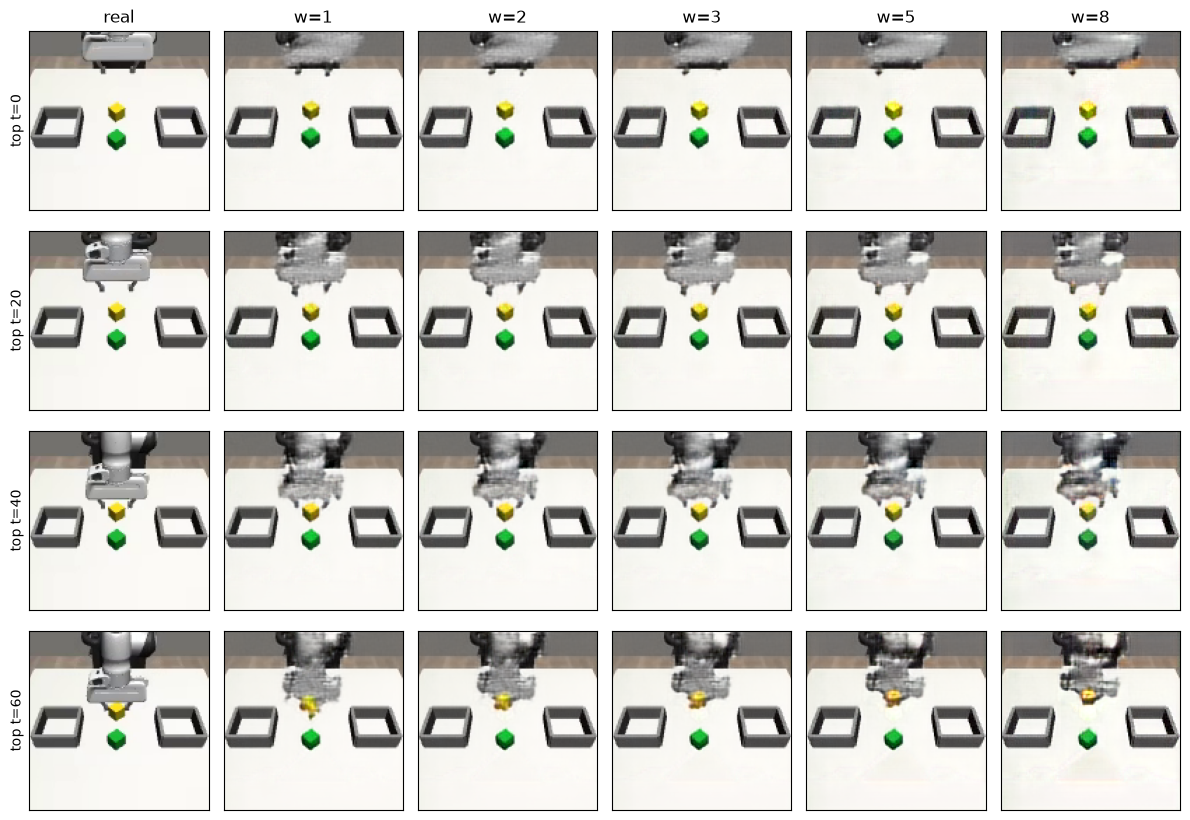

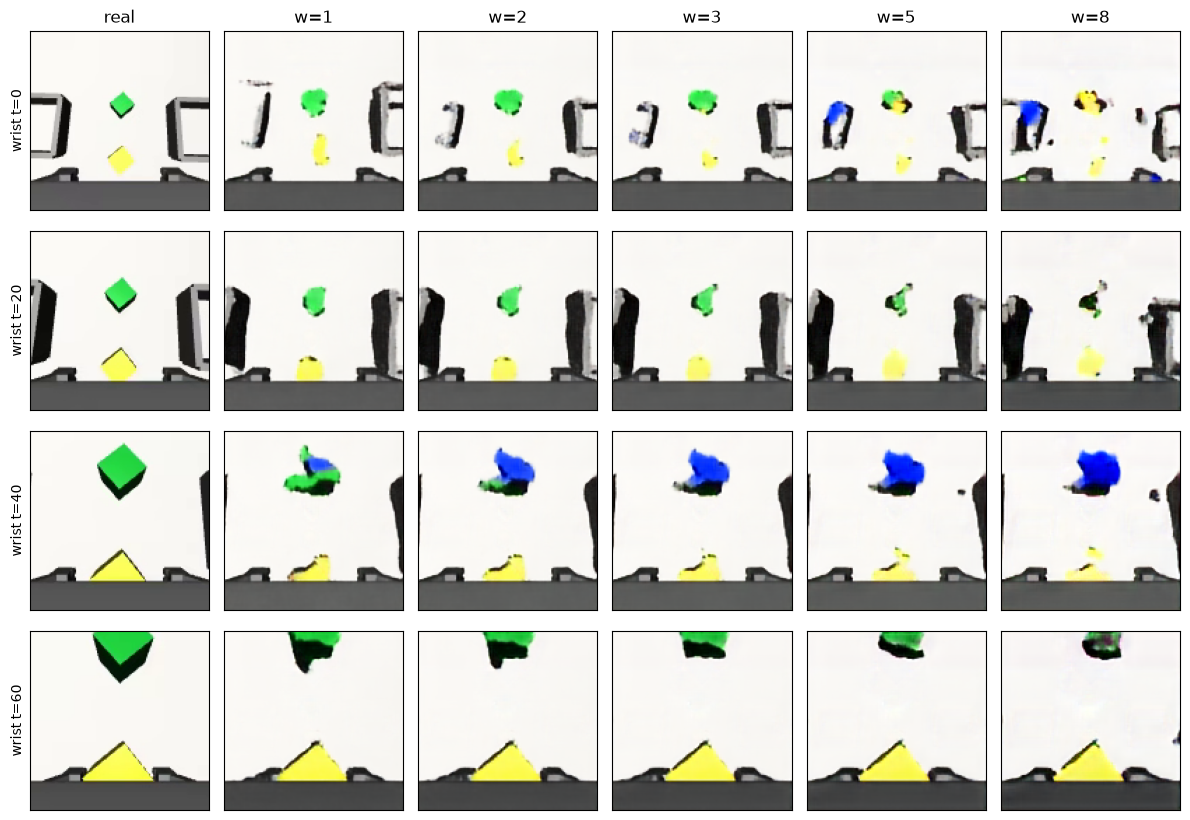

In [ ]:
ne = [e for e in val_eps if demo_slot[e] == 0][0]
nr = np.flatnonzero(data['episode'] == ne)[[0, 20, 40, 60]]
ws_ = (1.0, 2.0, 3.0, 5.0, 8.0)
dreams_w = {w: dream6(frames(nr), wframes(nr), *fields(nr), w=w) for w in ws_}
print(prompts[data['task'][nr[0]]])
for cam, ci in (('top', 0), ('wrist', 1)):
    real = (frames if cam == 'top' else wframes)(nr + K)
    fig, axs = plt.subplots(len(nr), 1 + len(ws_), figsize=(2 * (1 + len(ws_)), 2.1 * len(nr)))
    for r in range(len(nr)):
        for c, (name, img) in enumerate(
            [('real', real)] + [(f'w={w:g}', dreams_w[w][ci]) for w in ws_]
        ):
            axs[r, c].imshow(((img[r].permute(1, 2, 0) + 1) / 2).float().cpu().numpy())
            axs[r, c].set_xticks([]), axs[r, c].set_yticks([])
            if r == 0:
                axs[r, c].set_title(name)
            if c == 0:
                axs[r, c].set_ylabel(f'{cam} t={[0, 20, 40, 60][r]}')
    plt.tight_layout()
    plt.show()

## Step 21: guide only the top camera

The strip: guidance changes the top dream little and wrecks the wrist dream (invented colours) at high w. Guide only the top half of the dream, wrist at w = 1, with step 20's IDM.


In [ ]:
@torch.no_grad()
def dream6s(now, wrist, colour, side, w_top, w_wrist, n=20, seed=0):
    # dream6() with its own guidance strength per camera half -> (top, wrist) t+K
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn(len(now), 6, 128, 128, device=dev, generator=g)
    B = len(now)
    blank_c, blank_s = torch.full_like(colour, BLANK[0]), torch.full_like(side, BLANK[1])
    w = torch.tensor([w_top] * 3 + [w_wrist] * 3, device=dev)[None, :, None, None]
    for i in range(n):
        tau = i / n
        both = net6(
            now.repeat(2, 1, 1, 1), wrist.repeat(2, 1, 1, 1), x.repeat(2, 1, 1, 1),
            torch.full((2 * B,), tau, device=dev), torch.cat([colour, blank_c]),
            torch.cat([side, blank_s]),
        )
        guess = both[B:] + w * (both[:B] - both[B:])
        x = x + (guess - x) / (1 - tau) / n
    x = x.clamp(-1, 1)
    return x[:, :3], x[:, 3:]


class DreamFuture6s:
    # DreamFuture6 with per-camera guidance
    def __init__(self, colour, side, w_top, w_wrist):
        self.colour, self.side, self.w_top, self.w_wrist = colour, side, w_top, w_wrist

    def reset(self):
        pass

    def observe(self, obs, imagine):
        if not imagine:
            return None
        top, wrist = dream6s(
            to_t(obs.images['top']),
            to_t(obs.images['wrist']),
            self.colour,
            self.side,
            self.w_top,
            self.w_wrist,
        )
        return [Observation(state=obs.state, images={'top': to_img(top), 'wrist': to_img(wrist)})]


def cfg_job3(job):
    # (w_top, w_wrist, seed) -> (success, failure mode, half wrong, steps); IDM of step 20
    w_top, w_wrist, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    net = IDMPolicy.load_net(REPO_IDM, dev)[0]
    net.load_state_dict(run9['weights'])
    policy = IDMPolicy(net, DreamFuture6s(colour, side, w_top, w_wrist), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def cfg_grid3(ws: tuple = ((3.0, 1.0), (5.0, 1.0), (8.0, 1.0)), n: int = 60, start: int = 1000):
    # cfg_job3 for each (w_top, w_wrist) on n seeds, 8 spawned workers -> {(w_top, w_wrist, seed): result}
    jobs = [(wt, ww, s) for wt, ww in ws for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(jobs, pool.map(cfg_job3, jobs, chunksize=1)))

cfg_grid3: not cached, will compute


In [ ]:
split_g = cfg_grid3()
for s in (0, 1):
    rows_ = [('both w=3 (step 20)', [r for (w_, k), r in cfg2.items() if slot[k] == s])]
    rows_ += [
        (
            f'top w={wt:g}, wrist 1',
            [r for (a, b, k), r in split_g.items() if (a, b) == (wt, 1.0) and slot[k] == s],
        )
        for wt in (3.0, 5.0, 8.0)
    ]
    for name, rs in rows_:
        print(
            f'{"near" if s == 0 else "far "}  {name:19s} {sum(x[0] for x in rs)}/{len(rs)}  {dict(Counter(x[1] for x in rs if not x[0]))}'
        )

near  both w=3 (step 20)  14/39  {'wrong_target': 11, 'no_grasp': 13, 'dropped': 1}
near  top w=3, wrist 1    10/39  {'wrong_target': 15, 'no_grasp': 13, 'dropped': 1}
near  top w=5, wrist 1    11/39  {'wrong_target': 16, 'no_grasp': 12}
near  top w=8, wrist 1    10/39  {'no_grasp': 14, 'wrong_target': 14, 'dropped': 1}
far   both w=3 (step 20)  15/21  {'no_grasp': 6}
far   top w=3, wrist 1    15/21  {'no_grasp': 5, 'wrong_target': 1}
far   top w=5, wrist 1    12/21  {'no_grasp': 9}
far   top w=8, wrist 1    10/21  {'no_grasp': 9, 'dropped': 2}


## Step 22: the past, t-10 ... t-60

Step 17's t-60 test ran with the raw repo IDM, which failed on any dream, so it said little. Retry on the best setup (step 20: guidance w=3 + IDM fine-tuned on its dreams, 29/60) with the most context: top + wrist at t-10, t-20, ..., t-60 (the episode's first frame before the start). Risk: copycat (T1: 3 past frames 17 -> 11/20).


In [ ]:
PAST = (10, 20, 30, 40, 50, 60)
pasts = {
    o: np.maximum(np.arange(len(data['episode'])) - o, first) for o in PAST
}  # row t -> row t-o, clamped to the start


def hist(rows):
    # rows -> [B, 36, 128, 128]: top and wrist at t-10 ... t-60, in [-1, 1] on the GPU
    return torch.cat([f(pasts[o][rows]) for o in PAST for f in (frames, wframes)], 1)


class UNet8(UNet6):
    # UNet6 + 6 past frames per camera: [top t, wrist t, history (36 ch), noisy top + wrist t+10] -> clean top + wrist t+10
    def __init__(self):
        super().__init__()
        self.blocks['down1'] = down(48, 64)

    def forward(self, now, wrist, past_, noisy, tau, colour, side):
        return UNet2.forward(self, torch.cat([now, wrist, past_], 1), noisy, tau, colour, side)


unet8 = UNet8().to(dev)
rows = np.flatnonzero(data['episode'] == 0)[[0, 100]]
with torch.no_grad():
    out = unet8(
        frames(rows),
        wframes(rows),
        hist(rows),
        torch.randn(2, 6, 128, 128, device=dev),
        torch.rand(2, device=dev),
        *fields(rows),
    )
print(
    out.shape,
    f'{sum(p.numel() for p in unet8.parameters()) / 1e6:.2f}M params',
    [int(pasts[o][rows[1]]) for o in PAST],
)

torch.Size([2, 6, 128, 128]) 1.36M params [90, 80, 70, 60, 50, 40]


In [ ]:
@cache
def train8(steps: int = 10000, B: int = 32, lr: float = 3e-4, seed: int = 0, p_blank: float = 0.1):
    # train6() with a fresh UNet8 (+ t-10 ... t-60) -> weights (CPU), log rows [step, train loss, val top, val wrist]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = UNet8().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)
    g = torch.Generator(device=dev).manual_seed(1)
    v_noise, v_tau = (
        torch.randn(512, 6, 128, 128, device=dev, generator=g),
        torch.rand(512, device=dev, generator=g),
    )

    def both(rows):
        # rows -> [B, 6, 128, 128]: top and wrist frames stacked on channels
        return torch.cat([frames(rows), wframes(rows)], 1)

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        fut, noise, tau = (
            both(b + K),
            torch.randn(B, 6, 128, 128, device=dev),
            torch.rand(B, device=dev),
        )
        tw = tau[:, None, None, None]
        colour, side = fields(b)
        blank = torch.rand(B, device=dev) < p_blank
        colour, side = colour.masked_fill(blank, BLANK[0]), side.masked_fill(blank, BLANK[1])
        with torch.autocast('cuda', dtype=torch.bfloat16):
            pred = net(
                frames(b), wframes(b), hist(b), (1 - tw) * noise + tw * fut, tau, colour, side
            )
            loss = (pred.float() - fut).square().mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        if step % 1000 == 0:
            vt = vw = 0.0
            with torch.no_grad(), torch.autocast('cuda', dtype=torch.bfloat16):
                for i in range(0, 512, 64):
                    vb, n, t = vr[i : i + 64], v_noise[i : i + 64], v_tau[i : i + 64]
                    fut, tw = both(vb + K), t[:, None, None, None]
                    err = (
                        net(
                            frames(vb),
                            wframes(vb),
                            hist(vb),
                            (1 - tw) * n + tw * fut,
                            t,
                            *fields(vb),
                        ).float()
                        - fut
                    ).square()
                    vt += err[:, :3].mean().item() / 8
                    vw += err[:, 3:].mean().item() / 8
            log.append([step, loss.item(), vt, vw])
            print(
                f'{step:5d}  train {loss.item():.4f}   val top {vt:.4f}  wrist {vw:.4f}', flush=True
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

train8: not cached, will compute


In [80]:
run11 = train8(steps=30000)

 1000  train 0.0248   val top 0.0206  wrist 0.0261
 2000  train 0.0218   val top 0.0142  wrist 0.0198
 3000  train 0.0129   val top 0.0114  wrist 0.0175
 4000  train 0.0124   val top 0.0096  wrist 0.0147
 5000  train 0.0137   val top 0.0088  wrist 0.0133
 6000  train 0.0110   val top 0.0085  wrist 0.0126
 7000  train 0.0097   val top 0.0079  wrist 0.0119
 8000  train 0.0089   val top 0.0076  wrist 0.0113
 9000  train 0.0105   val top 0.0068  wrist 0.0109
10000  train 0.0095   val top 0.0067  wrist 0.0106
11000  train 0.0093   val top 0.0065  wrist 0.0105
12000  train 0.0082   val top 0.0064  wrist 0.0100
13000  train 0.0070   val top 0.0060  wrist 0.0096
14000  train 0.0079   val top 0.0059  wrist 0.0095
15000  train 0.0073   val top 0.0057  wrist 0.0090
16000  train 0.0065   val top 0.0057  wrist 0.0088
17000  train 0.0098   val top 0.0056  wrist 0.0089
18000  train 0.0073   val top 0.0055  wrist 0.0086
19000  train 0.0052   val top 0.0054  wrist 0.0084
20000  train 0.0051   val top 0

In [81]:
net8 = UNet8().to(dev).eval()
net8.load_state_dict(run11['weights'])


@torch.no_grad()
def dream8(now, wrist, past_, colour, side, w, n=20, seed=0):
    # dream6() for UNet8: + history [B, 36, 128, 128] -> guided (top, wrist) t+K
    g = torch.Generator(device=dev).manual_seed(seed)
    x = torch.randn(len(now), 6, 128, 128, device=dev, generator=g)
    B = len(now)
    blank_c, blank_s = torch.full_like(colour, BLANK[0]), torch.full_like(side, BLANK[1])
    for i in range(n):
        tau = i / n
        both = net8(
            now.repeat(2, 1, 1, 1), wrist.repeat(2, 1, 1, 1), past_.repeat(2, 1, 1, 1), x.repeat(2, 1, 1, 1),
            torch.full((2 * B,), tau, device=dev), torch.cat([colour, blank_c]), torch.cat([side, blank_s]),
        )
        guess = both[B:] + w * (both[:B] - both[B:])
        x = x + (guess - x) / (1 - tau) / n
    x = x.clamp(-1, 1)
    return x[:, :3], x[:, 3:]

In [82]:
# UNet8 w=3 dreams for every train / val row t (from its real past), stored at row t+10 (~3 GB, not cached)
dreamt8 = dict(
    top=np.zeros((len(data['top']), 3, 128, 128), np.uint8),
    wrist=np.zeros((len(data['top']), 3, 128, 128), np.uint8),
)
for i, c in enumerate(np.array_split(dream_rows, len(dream_rows) // 256)):
    top_, wrist_ = dream8(frames(c), wframes(c), hist(c), *fields(c), w=3.0, seed=i)
    dreamt8['top'][c + K] = ((top_ + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()
    dreamt8['wrist'][c + K] = ((wrist_ + 1) * 127.5).round().clamp(0, 255).byte().cpu().numpy()
    if i % 20 == 0:
        print(i, 'of', len(dream_rows) // 256, 'batches', flush=True)
print(len(dream_rows), 'rows dreamed')

0 of 124 batches
20 of 124 batches
40 of 124 batches
60 of 124 batches
80 of 124 batches
100 of 124 batches
120 of 124 batches
31885 rows dreamed


In [83]:
@cache
def finetune_idm3(steps: int = 10000, B: int = 64, lr: float = 1e-4, seed: int = 0):
    # finetune_idm() on UNet8 w=3 dreams: the repo IDM from its checkpoint, trained on (real t, dream t+10, state) -> real actions, L1 normalised
    # -> weights (CPU), log rows [step, train loss, val L1 on dreams, val L1 on real futures]
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = IDMPolicy.load_net(REPO_IDM, dev)[0].to(dev).train()
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    vr = np.random.default_rng(1).choice(split['val'], 512, replace=False)

    def cams(src, rows):
        # {'top', 'wrist'} uint8 arrays, rows -> {camera: [B, 3, 128, 128] float in [0, 1] on the GPU}
        return {c: torch.tensor(src[c][rows], device=dev).float() / 255 for c in ('top', 'wrist')}

    def err(rows, fut_src):
        state = torch.tensor(data['state'][rows], device=dev)
        target = net.action_norm.normalize(
            torch.tensor(data['action'][rows[:, None] + np.arange(K)], device=dev)
        )
        return (net(cams(data, rows), cams(fut_src, rows + K), state) - target).abs().mean()

    log = []
    for step in range(1, steps + 1):
        b = rng.choice(split['train'], B)
        now, fut = shift_together(cams(data, b), cams(dreamt8, b + K), 4)
        state = torch.tensor(data['state'][b], device=dev)
        target = net.action_norm.normalize(
            torch.tensor(data['action'][b[:, None] + np.arange(K)], device=dev)
        )
        loss = (net(now, fut, state) - target).abs().mean()
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
        opt.step()
        sched.step()
        if step % 1000 == 0 or step == 1:
            net.eval()
            with torch.no_grad():
                vd = np.mean([err(c, dreamt8).item() for c in np.split(vr, 8)])
                vreal = np.mean([err(c, data).item() for c in np.split(vr, 8)])
            net.train()
            log.append([step, loss.item(), vd, vreal])
            print(
                f'{step:5d}  train {loss.item():.4f}   val on dreams {vd:.4f}  on real futures {vreal:.4f}',
                flush=True,
            )
    return frozendict(weights={k: v.cpu() for k, v in net.state_dict().items()}, log=np.array(log))

finetune_idm3: not cached, will compute


In [84]:
run12 = finetune_idm3()

    1  train 0.0712   val on dreams 0.0479  on real futures 0.0348
 1000  train 0.0580   val on dreams 0.0428  on real futures 0.0397
 2000  train 0.0560   val on dreams 0.0411  on real futures 0.0387
 3000  train 0.0584   val on dreams 0.0399  on real futures 0.0381
 4000  train 0.0540   val on dreams 0.0390  on real futures 0.0373
 5000  train 0.0569   val on dreams 0.0394  on real futures 0.0378
 6000  train 0.0622   val on dreams 0.0387  on real futures 0.0374
 7000  train 0.0600   val on dreams 0.0376  on real futures 0.0362
 8000  train 0.0536   val on dreams 0.0371  on real futures 0.0357
 9000  train 0.0551   val on dreams 0.0367  on real futures 0.0355
10000  train 0.0520   val on dreams 0.0367  on real futures 0.0355


In [85]:
class DreamFuture8:
    # DreamFuture6 for UNet8: remembers every live frame, dreams from t and t-10 ... t-60
    def __init__(self, colour, side, w):
        self.colour, self.side, self.w = colour, side, w

    def reset(self):
        self.seen = []

    def observe(self, obs, imagine):
        self.seen.append(obs)
        if not imagine:
            return None
        t = len(self.seen) - 1
        then = [self.seen[max(t - o, 0)] for o in PAST]
        past_ = torch.cat([to_t(o.images[c]) for o in then for c in ('top', 'wrist')], 1)
        top, wrist = dream8(
            to_t(obs.images['top']),
            to_t(obs.images['wrist']),
            past_,
            self.colour,
            self.side,
            self.w,
        )
        return [Observation(state=obs.state, images={'top': to_img(top), 'wrist': to_img(wrist)})]


def cfg_job5(job):
    # (w, seed) -> (success, failure mode, half wrong, steps): UNet8 guided dreams, IDM fine-tuned on them
    w, seed = job
    env = InstructedPickPlace(TaskConfig.load(), pairs='seen', wording='template')
    obs = env.reset(seed=seed)
    colour, side = (torch.tensor([i], device=dev) for i in parse(env.prompt))
    net = IDMPolicy.load_net(REPO_IDM, dev)[0]
    net.load_state_dict(run12['weights'])
    policy = IDMPolicy(net, DreamFuture8(colour, side, w), device=dev)
    policy.reset()
    t = 0
    while True:
        res = env.step(policy(obs))
        obs, t = res.observation, t + 1
        if res.terminated or res.truncated:
            return (
                res.success,
                str(res.failure_mode),
                None if res.success else env.instruction_failure(),
                t,
            )


@cache
def cfg_grid5(ws: tuple = (3.0,), n: int = 60, start: int = 1000):
    # cfg_job5 for each w on n seeds, 8 spawned workers -> {(w, seed): result}
    jobs = [(w, s) for w in ws for s in range(start, start + n)]
    with mp.get_context('spawn').Pool(8, initializer=quiet) as pool:
        return dict(zip(jobs, pool.map(cfg_job5, jobs, chunksize=1)))

cfg_grid5: not cached, will compute


In [86]:
cfg5 = cfg_grid5()
for s in (0, 1):
    for name, g_ in (('step 20, no past', cfg2), ('UNet8, t-10 ... t-60', cfg5)):
        rs = [r for (w_, k), r in g_.items() if slot[k] == s]
        print(
            f'{"near" if s == 0 else "far "}  {name:21s} {sum(x[0] for x in rs)}/{len(rs)}  {dict(Counter(x[1] for x in rs if not x[0]))}'
        )

near  step 20, no past      14/39  {'wrong_target': 11, 'no_grasp': 13, 'dropped': 1}
near  UNet8, t-10 ... t-60  15/39  {'no_grasp': 13, 'wrong_target': 11}
far   step 20, no past      15/21  {'no_grasp': 6}
far   UNet8, t-10 ... t-60  13/21  {'no_grasp': 7, 'dropped': 1}
